# Viken KHATCHERIAN OpenClassrooms — Projet 11 : Reinforcement Learning

# Mission — Pilotez l'atterrisseur lunaire Eagle - 1

## Étape 1-1 — test disponibilité environnement, bibliothèques, 8 variables d'observation et 4 actions possibles

In [1]:
import gymnasium as gym
import stable_baselines3 as sb3
import torch

print("Gymnasium :", gym.__version__)
print("Stable-Baselines3 :", sb3.__version__)
print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())

env = gym.make("LunarLander-v3")

print("\nEnvironnement :", env.spec.id)
print("Espace d'observation :", env.observation_space)
print("Espace d'action :", env.action_space)

observation, info = env.reset(seed=42)

print("\nObservation initiale :", observation)
print("Forme de l'observation :", observation.shape)
print("Action échantillonnée :", env.action_space.sample())

env.close()


Gymnasium : 1.4.0
Stable-Baselines3 : 2.9.0
PyTorch : 2.9.1+cu128
CUDA disponible : True

Environnement : LunarLander-v3
Espace d'observation : Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espace d'action : Discrete(4)

Observation initiale : [ 0.00229702  1.4181306   0.2326471   0.3204666  -0.00265488 -0.05269805
  0.          0.        ]
Forme de l'observation : (8,)
Action échantillonnée : 2


## Etape 1.2 — Exploration de l’environnement LunarLander-v3

L’environnement `LunarLander-v3` simule l’atterrissage d’un module lunaire. L’objectif de l’agent est de contrôler ses mouvements afin d’atteindre la zone d’atterrissage en limitant les risques de collision.

**Espace d’observation**

L’environnement fournit huit variables numériques décrivant l’état du module :

- Position horizontale et verticale.
- Vitesses horizontale et verticale.
- Angle du module et vitesse angulaire.
- Contact de la jambe gauche avec le sol.
- Contact de la jambe droite avec le sol.

Ces observations permettent à l’agent d’estimer la situation du module à chaque étape.

**Espace d’action**

L’agent dispose de quatre actions discrètes :

- `0` : ne pas activer de propulseur.
- `1` : activer le propulseur latéral gauche.
- `2` : activer le propulseur principal.
- `3` : activer le propulseur latéral droit.

**Choix de l’algorithme**

Nous utiliserons l’algorithme DQN (*Deep Q-Network*) de Stable-Baselines3. Il est adapté à cet environnement, car l’espace d’actions est discret. L’agent apprendra progressivement à choisir les actions qui maximisent la récompense cumulée.

Ci-dessous réalisation d'une expérience qui permet de visualiser la manière dont évoluent les observations et les récompenses lorsqu’on applique des actions aléatoires. **Elle ne constitue pas encore un entraînement.** 

Nous voulons avec cette expérience vérifier que:
- les observations évoluent à chaque action
- que l'environnement renvoie une récompense
- que l'épisode se termine correctement ou atteint sa limite

Le résultat sera variable car les actions sont choisies aléatoirement

In [2]:
import gymnasium as gym
import numpy as np

env = gym.make("LunarLander-v3")

observation, info = env.reset(seed=42)
total_reward = 0
nb_steps = 0

for step in range(200):
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)

    total_reward += reward
    nb_steps += 1

    if step < 5:
        print(f"Étape {step + 1}")
        print("  Action :", action)
        print("  Observation :", np.round(observation, 3))
        print("  Récompense :", round(float(reward), 3))

    if terminated or truncated:
        break

print("\nNombre d'étapes :", nb_steps)
print("Récompense totale :", round(float(total_reward), 2))
print("Épisode terminé :", terminated)
print("Limite de temps atteinte :", truncated)

env.close()


Étape 1
  Action : 2
  Observation : [ 0.004  1.426  0.217  0.344 -0.006 -0.067  0.     0.   ]
  Récompense : -2.497
Étape 2
  Action : 0
  Observation : [ 0.007  1.433  0.217  0.317 -0.009 -0.067  0.     0.   ]
  Récompense : 1.173
Étape 3
  Action : 0
  Observation : [ 0.009  1.44   0.217  0.291 -0.013 -0.067  0.     0.   ]
  Récompense : 1.176
Étape 4
  Action : 0
  Observation : [ 0.011  1.445  0.217  0.264 -0.016 -0.067  0.     0.   ]
  Récompense : 1.165
Étape 5
  Action : 1
  Observation : [ 0.013  1.451  0.206  0.238 -0.017 -0.022  0.     0.   ]
  Récompense : 2.063

Nombre d'étapes : 108
Récompense totale : -123.01
Épisode terminé : True
Limite de temps atteinte : False


| Indicateur                  | Résultat | Interprétation |
|-----------------------------|----------|----------------|
| Nombre d’étapes             | 107      | L’épisode s’est terminé avant la limite de 200 étapes de notre boucle. |
| Récompense totale           | -138,31  | L’agent aléatoire a obtenu une récompense négative. |
| Épisode terminé             | `True`   | L’environnement a signalé une fin d’épisode. |
| Limite de temps atteinte    | `False`  | La fin n’est pas due à la limite de temps Gymnasium. |

Les cinq premières étapes montrent que les observations changent en fonction des actions et que les récompenses peuvent être positives ou négatives.

Nous avons exécuté un épisode de `LunarLander-v3` en sélectionnant les actions aléatoirement. Cette expérience permet de vérifier le fonctionnement de l’environnement, l’évolution des observations et le calcul des récompenses.

L’épisode s’est terminé après 107 étapes avec une récompense cumulée de **-138,31**. L’environnement a signalé une fin d’épisode, sans atteindre la limite de temps imposée par notre boucle.

Cette performance négative illustre les limites d’une stratégie aléatoire. L’agent ne tient pas compte de la position, de la vitesse ou de l’orientation du module pour choisir ses actions.

**Conclusion :** un agent qui choisit ses actions au hasard ne sait pas contrôler correctement l’atterrisseur. Cette expérience constitue notre point de départ qualitatif, mais pas encore notre référence quantitative : celle-ci sera mesurée avec un modèle DQN entraîné.

## Formatage et représentation des données

L’environnement LunarLander-v3 fournit à chaque étape une observation composée de huit valeurs numériques. Ces valeurs décrivent notamment la position et la vitesse du module, son orientation et le contact de ses jambes avec le sol.

L’observation est renvoyée sous la forme d’un tableau NumPy. Elle contient huit valeurs numériques, correspondant à un vecteur de dimension 8.

Dans notre projet, ces observations sont utilisées par l’agent DQN pour estimer la valeur des différentes actions possibles. L’agent reçoit également la récompense obtenue après chaque action et l’observation suivante, ce qui lui permet d’apprendre à améliorer sa politique.

Nous conservons les huit composantes de l’observation dans leur ordre défini par l’environnement. Nous ne réalisons pas de normalisation manuelle des observations dans notre code : le modèle DQN de Stable-Baselines3 reçoit directement les observations de l’environnement, selon le format attendu par la bibliothèque.

Lors des appels à l’API, l’observation est transmise sous forme de huit valeurs numériques, puis convertie en tableau NumPy de type float32 avant la prédiction. Cette représentation garantit une entrée compatible avec le modèle et permet de vérifier que l’API reçoit bien une observation de dimension correcte.

In [3]:
# Vérification du format des observations
env = gym.make("LunarLander-v3")

observation, info = env.reset(seed=42)

print("Espace d'observation :", env.observation_space)
print("Type de l'observation :", type(observation))
print("Forme de l'observation :", observation.shape)
print("Type numérique :", observation.dtype)
print("Nombre de valeurs :", observation.size)

# Conversion explicite pour illustrer le format utilisé à l'entrée de l'API
observation_api = np.asarray(observation, dtype=np.float32)

print("Forme après conversion :", observation_api.shape)
print("Type après conversion :", observation_api.dtype)

assert observation.shape == (8,)
assert observation_api.shape == (8,)
assert observation_api.dtype == np.float32

env.close()

Espace d'observation : Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Type de l'observation : <class 'numpy.ndarray'>
Forme de l'observation : (8,)
Type numérique : float32
Nombre de valeurs : 8
Forme après conversion : (8,)
Type après conversion : float32


## Etape 1.3 — Création et entraînement du modèle de référence DQN

### Justification du choix de l'algorithme DQN

#### Choix de l'algorithme : Deep Q-Network (DQN)

L'environnement `LunarLander-v3` possède un espace d'observation composé de huit valeurs numériques et un espace d'action discret comprenant quatre actions possibles. Ces caractéristiques sont compatibles avec l'algorithme **Deep Q-Network (DQN)**.

DQN est un algorithme d'apprentissage par renforcement fondé sur l'apprentissage d'une fonction de valeur d'action, notée \(Q(s,a)\). Un réseau de neurones estime la valeur des actions possibles pour un état donné. L'agent apprend progressivement à sélectionner les actions qui maximisent la récompense cumulée.

Nous avons choisi DQN pour les raisons suivantes :

- **Compatibilité avec l'environnement :** DQN est adapté aux espaces d'action discrets, comme celui de `LunarLander-v3`.
- **Capacité d'apprentissage :** le réseau de neurones permet d'estimer les valeurs des actions à partir des huit variables décrivant l'état du module lunaire.
- **Stabilisation de l'apprentissage :** l'implémentation de Stable-Baselines3 utilise notamment un replay buffer et un réseau cible pour améliorer la stabilité de l'entraînement.
- **Comparaison des performances :** nous commençons par un modèle de référence avec les paramètres par défaut, puis nous faisons varier certains hyperparamètres afin d'évaluer leur influence sur les récompenses obtenues.

L'implémentation de référence utilise `DQN` de Stable-Baselines3 avec la politique `MlpPolicy`, adaptée aux observations vectorielles de l'environnement. Les performances seront ensuite évaluées sur 100 épisodes afin de comparer les différentes expérimentations et de sélectionner le modèle final.


In [12]:
# Création du modèle DQN de référence

import gymnasium as gym
from stable_baselines3 import DQN

# Création de l'environnement d'entraînement
env = gym.make("LunarLander-v3")

# Création du modèle DQN avec les paramètres par défaut
model_ref = DQN(
    policy="MlpPolicy",
    env=env,
    verbose=1,
    tensorboard_log="./logs/lunarlander/"
)

print("\nModèle de référence créé.")
print("Algorithme :", type(model_ref).__name__)
print("Politique :", type(model_ref.policy).__name__)
print("Périphérique :", model_ref.device)
print("Taille du buffer :", model_ref.buffer_size)
print("Taille du batch :", model_ref.batch_size)
print("Taux d'apprentissage :", model_ref.learning_rate)
print("Facteur gamma :", model_ref.gamma)


Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.

Modèle de référence créé.
Algorithme : DQN
Politique : DQNPolicy
Périphérique : cuda
Taille du buffer : 1000000
Taille du batch : 32
Taux d'apprentissage : 0.0001
Facteur gamma : 0.99


Les paramètres affichés correspondent aux valeurs par défaut de DQN dans Stable-Baseline3:

| Paramètre       | Valeur    | Rôle                                      |
|-----------------|-----------|-------------------------------------------|
| `buffer_size`   | 1 000 000 | Capacité maximale du replay buffer        |
| `batch_size`    | 32        | Nombre d’expériences utilisées pour une mise à jour |
| `learning_rate` | 0,0001    | Taux d’apprentissage                      |
| `gamma`         | 0,99      | Importance des récompenses futures        |
| `device`        | `cuda`    | Calcul sur le GPU                         |

Nous choisissons de conserver ces valeurs pour obtenir une première référence, sans chercher à optimiser le modèle pour le moment.

In [13]:
# Entraîner le modèle de référence 
# Premier entraînement avec 100000 interactions avec l'environnement.


from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3.common.callbacks import BaseCallback

# Dossier de sauvegarde des métriques et des figures
PROJECT_DIR = Path(
    "/mnt/projects/vk_oc_projet11_reinforcement_learning"
)
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# Callback pour enregistrer les récompenses de chaque épisode
class RewardLoggerCallback(BaseCallback):
    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.episode_rewards = []
        self.episode_lengths = []

    def _on_step(self) -> bool:
        for info in self.locals.get("infos", []):
            if "episode" in info:
                self.episode_rewards.append(
                    info["episode"]["r"]
                )
                self.episode_lengths.append(
                    info["episode"]["l"]
                )
        return True


# Nombre d'interactions pour l'entraînement de référence
TIMESTEPS_REF = 100_000

# Création du collecteur de récompenses
reward_callback = RewardLoggerCallback()

# Entraînement du modèle DQN
model_ref.learn(
    total_timesteps=TIMESTEPS_REF,
    tb_log_name="DQN_reference",
    callback=reward_callback
)

print("\nEntraînement de référence terminé.")
print("Nombre d'épisodes enregistrés :", len(reward_callback.episode_rewards))



Logging to ./logs/lunarlander/DQN_reference_3
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 116      |
|    ep_rew_mean      | -212     |
|    exploration_rate | 0.956    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 4032     |
|    time_elapsed     | 0        |
|    total_timesteps  | 464      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 1.67     |
|    n_updates        | 90       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 106      |
|    ep_rew_mean      | -186     |
|    exploration_rate | 0.919    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 3770     |
|    time_elapsed     | 0        |
|    total_timesteps  | 849      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss

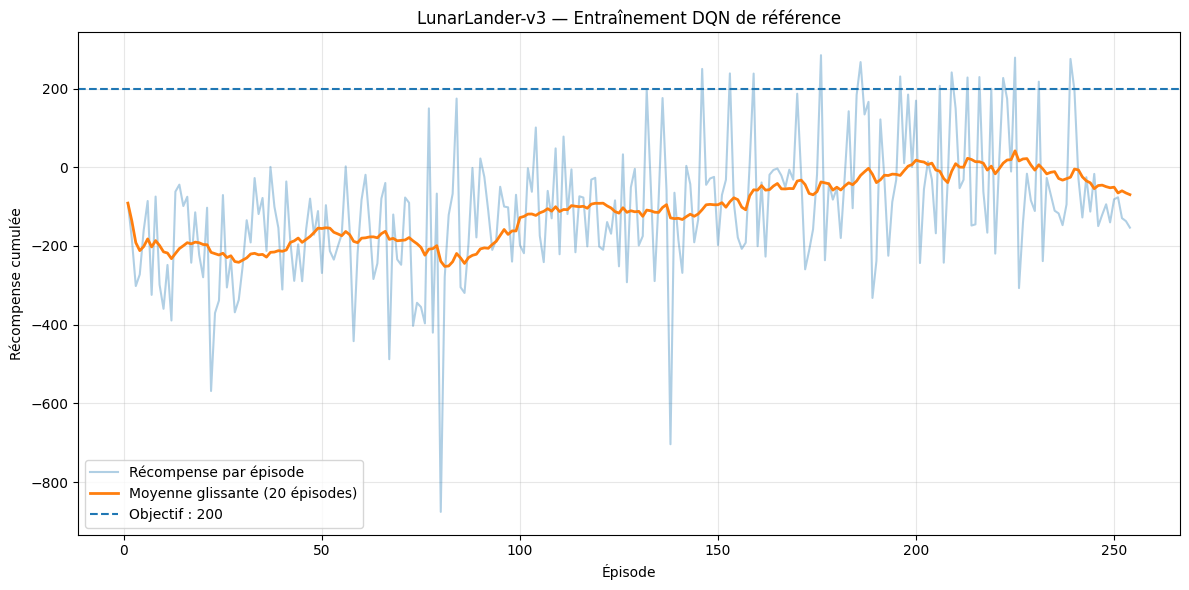

Données CSV : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_reference_rewards.csv
Données NumPy : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_reference_rewards.npy
Figure PNG : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/figures/dqn_lunarlander_reference_learning_curve.png
Récompense moyenne des épisodes enregistrés : -107.03


In [14]:
# Enregistrer les données et tracer les courbes

import pandas as pd

rewards = np.asarray(reward_callback.episode_rewards, dtype=float)
lengths = np.asarray(reward_callback.episode_lengths, dtype=int)
episodes = np.arange(1, len(rewards) + 1)

# Moyenne glissante sur 20 épisodes
rolling_mean = pd.Series(rewards).rolling(
    window=20, min_periods=1
).mean().to_numpy()

# Sauvegarde des métriques
metrics_df = pd.DataFrame({
    "episode": episodes,
    "reward": rewards,
    "episode_length": lengths,
    "rolling_mean_20": rolling_mean
})

csv_path = METRICS_DIR / "dqn_lunarlander_reference_rewards.csv"
npy_path = METRICS_DIR / "dqn_lunarlander_reference_rewards.npy"

metrics_df.to_csv(csv_path, index=False)
np.save(npy_path, rewards)

# Figure : récompenses par épisode et tendance
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    episodes,
    rewards,
    alpha=0.35,
    label="Récompense par épisode"
)
ax.plot(
    episodes,
    rolling_mean,
    linewidth=2,
    label="Moyenne glissante (20 épisodes)"
)
ax.axhline(
    y=200,
    linestyle="--",
    label="Objectif : 200"
)

ax.set_xlabel("Épisode")
ax.set_ylabel("Récompense cumulée")
ax.set_title("LunarLander-v3 — Entraînement DQN de référence")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

figure_path = FIGURES_DIR / "dqn_lunarlander_reference_learning_curve.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("Données CSV :", csv_path)
print("Données NumPy :", npy_path)
print("Figure PNG :", figure_path)
print("Récompense moyenne des épisodes enregistrés :", round(float(rewards.mean()), 2))


### Analyse de l’entraînement

| Indicateur                                           | Résultat final |
|------------------------------------------------------|---------------:|
| Interactions demandées                               |        100 000 |
| Dernier total d’interactions affiché dans les logs   |         97 005 |
| Épisodes enregistrés par le callback                 |            254 |
| Épisodes affichés dans le dernier journal périodique |            252 |
| Récompense moyenne récente (`ep_rew_mean`)           |          -25,6 |
| Durée moyenne récente (`ep_len_mean`)                |     516 étapes |
| Taux d’exploration (`exploration_rate`)              |           0,05 |
| Temps d’entraînement affiché                         |    29 secondes |

La différence entre les 100 000 interactions demandées et les 97 005 interactions du dernier journal périodique vient du fait que Stable-Baselines3 affiche ses statistiques à intervalles réguliers. Ce journal ne correspond donc pas nécessairement à la toute dernière interaction. L’appel `learn()` s’étant terminé normalement, l’entraînement est terminé.

Le callback a enregistré 254 épisodes, contre 252 dans le dernier journal périodique. Ces nombres peuvent différer, car les statistiques affichées par Stable-Baselines3 sont actualisées périodiquement.

### Interprétation des résultats

La récompense moyenne récente est de **-25,6 points**. Elle reste négative : malgré les mises à jour de son réseau, l’agent n’a pas encore appris une stratégie d’atterrissage suffisamment performante.

La durée moyenne récente est de 516 étapes. Cela indique que les épisodes sont relativement longs, mais cette durée ne suffit pas à évaluer la qualité de l’atterrissage : l’agent peut rester en vol sans réussir à se poser correctement.

Le taux d’exploration de 0,05 signifie que le mécanisme epsilon-greedy conserve 5 % d’exploration aléatoire. L’agent privilégie donc généralement les actions suggérées par son réseau, tout en maintenant une faible part d’exploration.

### Conclusion

Ce modèle constitue notre nouvelle référence pour la mission LunarLander. Ses performances restent insuffisantes par rapport à l’objectif fixé : obtenir une récompense moyenne d’au moins 200 points sur 100 épisodes d’évaluation.

Les résultats varient d’un entraînement à l’autre, même avec les mêmes hyperparamètres, car l’initialisation du réseau et les trajectoires explorées peuvent être différentes. Il est donc important de conserver les résultats et la courbe d’apprentissage de chaque expérience.

À l’étape 2, nous chercherons à améliorer les performances en modifiant un hyperparamètre à la fois, puis en évaluant les modèles sur 100 épisodes pour comparer leurs récompenses moyennes et leurs écarts-types.


## Etape 1-4 : évaluer puis sauvegarder le modèle de référence

In [15]:
# Evaluer le modèle sur 50 épisodes indépendants

import gymnasium as gym
import numpy as np

from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

# Environnement réservé à l'évaluation
env_eval = Monitor(gym.make("LunarLander-v3"))

# Évaluation sur 50 épisodes, sans exploration aléatoire
mean_reward_ref, std_reward_ref = evaluate_policy(
    model_ref,
    env_eval,
    n_eval_episodes=50,
    deterministic=True,
    return_episode_rewards=False
)

env_eval.close()

print("=== Évaluation du modèle DQN de référence ===")
print("Nombre d'épisodes : 50")
print(f"Récompense moyenne : {mean_reward_ref:.2f}")
print(f"Écart-type : {std_reward_ref:.2f}")
print(f"Objectif de 200 atteint : {mean_reward_ref >= 200}")


=== Évaluation du modèle DQN de référence ===
Nombre d'épisodes : 50
Récompense moyenne : -93.52
Écart-type : 93.00
Objectif de 200 atteint : False


### Remarques

La récompense moyenne obtenue lors de l'évaluation est de **-93,52**, et non de 200. Le seuil de 200 constitue l'objectif de performance de la mission que nous chercherons à atteindre à l'étape 2.

### Interprétation des résultats

**Entraînement :** GPU CUDA.

- **Algorithme :** DQN avec Stable-Baselines3.
- **Hyperparamètres :** valeurs par défaut de Stable-Baselines3.
- **Évaluation :** 50 épisodes indépendants, avec sélection déterministe des actions.

**Résultats**

| Indicateur                         | Valeur |
|------------------------------------|-------:|
| Nombre d'épisodes évalués          |     50 |
| Récompense moyenne                 | -93,52 |
| Écart-type des récompenses         |  93,00 |
| Seuil cible de 200 atteint         |    Non |

Nous disposons maintenant d'une référence chiffrée (*baseline*) pour comparer les prochaines expériences.

### Analyse

Le modèle de référence a été entraîné et évalué. Cependant, sa récompense moyenne de **-93,52** reste nettement inférieure à l'objectif de 200 points. L'écart-type de **93,00** indique une forte dispersion des récompenses entre les épisodes.

Ces résultats montrent que le modèle ne maîtrise pas encore suffisamment l'atterrissage sur LunarLander-v3. Les performances varient d'un épisode à l'autre, et les récompenses négatives indiquent que l'agent ne parvient pas encore à adopter une stratégie efficace de manière régulière.

La récompense moyenne mesurée lors de cette évaluation est différente de celle de 34,22 obtenue précédemment. Ces différences peuvent notamment provenir de la variabilité des épisodes et de la stochasticité de l'environnement. Pour comparer les prochaines expériences, nous conserverons cette dernière évaluation comme référence, en utilisant la même procédure d'évaluation.

À ce stade, aucune optimisation approfondie n'est recherchée : l'objectif est de disposer d'une référence fiable avant de modifier les hyperparamètres.

### Conclusion

Le modèle DQN de référence ne satisfait pas encore l'objectif de performance fixé. L'étape 2 portera sur l'amélioration progressive de ses performances, en modifiant les hyperparamètres de manière contrôlée et en évaluant chaque modèle sur 100 épisodes.

Nous comparerons notamment la récompense moyenne et l'écart-type afin de déterminer si les modifications permettent d'obtenir des atterrissages plus performants et plus réguliers.

In [16]:
# Sauvegarde du modèle de référence

from pathlib import Path

# Chemin du projet
PROJECT_DIR = Path(
    "/mnt/projects/vk_oc_projet11_reinforcement_learning"
)

# Dossier de sauvegarde des modèles
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Chemin du modèle de référence
MODEL_REF_PATH = MODELS_DIR / "dqn_lunarlander_reference_baseline"

# Sauvegarde du modèle
model_ref.save(str(MODEL_REF_PATH))

print("Modèle de référence sauvegardé avec succès.")
print("Fichier :", str(MODEL_REF_PATH) + ".zip")
print("Fichier présent :", (MODELS_DIR / "dqn_lunarlander_reference_baseline.zip").exists())


Modèle de référence sauvegardé avec succès.
Fichier : /mnt/projects/vk_oc_projet11_reinforcement_learning/models/dqn_lunarlander_reference_baseline.zip
Fichier présent : True


In [17]:
# Vérification de la possibilité de recharger le modèle de référence

from stable_baselines3 import DQN

# Rechargement du modèle de référence
model_ref_check = DQN.load(str(MODEL_REF_PATH))

print("Modèle rechargé avec succès.")
print("Algorithme :", type(model_ref_check).__name__)
print("Nombre d'actions :", model_ref_check.action_space.n)


Modèle rechargé avec succès.
Algorithme : DQN
Nombre d'actions : 4


## Etape 2 - Optimiser les hyperparamètres de l'agent

Un point important avant de commencer : ta baseline a obtenu une récompense moyenne de −93,52 sur 50 épisodes, avec un écart-type de 93,00. C’est notre résultat d’évaluation de référence. Le journal d’entraînement affichait, lui, une récompense récente de −25,6 : ces deux chiffres ne sont pas contradictoires, car ils sont calculés sur des épisodes différents.

L’objectif est maintenant d’obtenir une moyenne d’au moins 200 points sur 100 épisodes d’évaluation indépendants, avec une variabilité raisonnable. Nous ne pouvons pas garantir à l’avance que ce seuil sera atteint, mais nous pouvons organiser les expériences pour maximiser nos chances et comprendre les résultats.

### Plan de travail de l’étape 2

#### 2.1 — Fiabiliser le protocole

Fixer les graines aléatoires, vérifier la sauvegarde de la baseline, définir les métriques et créer un journal d’expériences.

#### 2.2 — Construire les courbes de référence

Exploiter les récompenses par épisode, les moyennes glissantes et TensorBoard pour observer l’apprentissage.

#### 2.3 — Tester les hyperparamètres un par un avec aussi amélioration de modèles déjà obtenus sur les expériences précédentes

Commencer par le taux d’apprentissage, puis tester la durée d’entraînement et les autres paramètres en conservant un protocole commun pouvant inclure l'amélioration d'un modèle déjà obtenu à l'expérience N-1.

#### 2.4 — Évaluer et sélectionner le meilleur modèle

Évaluer les candidats sur 100 épisodes, comparer moyenne et écart-type, puis sauvegarder le meilleur agent validé.

**Règle méthodologique :** chaque expérience partira d’un nouveau modèle, sauf si nous étudions explicitement la poursuite d’un entraînement. Nous ne modifierons pas plusieurs hyperparamètres à la fois et nous garderons la baseline intacte.

In [18]:
# Étape 2.1 — Préparer un protocole expérimental fiable

from pathlib import Path
import json
import random

import gymnasium as gym
import numpy as np
import pandas as pd
import torch
import stable_baselines3 as sb3

# Racine du projet
PROJECT_DIR = Path(
    "/mnt/projects/vk_oc_projet11_reinforcement_learning"
)

# Dossiers de travail
MODELS_DIR = PROJECT_DIR / "models"
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
LOGS_DIR = PROJECT_DIR / "logs" / "lunarlander"

for directory in [MODELS_DIR, METRICS_DIR, FIGURES_DIR, LOGS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Modèle de référence sauvegardé à l'étape 1
BASELINE_PATH = MODELS_DIR / "dqn_lunarlander_reference_baseline"
BASELINE_FILE = Path(str(BASELINE_PATH) + ".zip")

print("=== Vérification du projet ===")
print("Gymnasium :", gym.__version__)
print("Stable-Baselines3 :", sb3.__version__)
print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
print("Fichier de référence présent :", BASELINE_FILE.exists())

if not BASELINE_FILE.exists():
    raise FileNotFoundError(
        f"Modèle de référence introuvable : {BASELINE_FILE}"
    )

# Journal des expériences : création uniquement s'il n'existe pas
EXPERIMENTS_CSV = METRICS_DIR / "lunarlander_experiments.csv"

if not EXPERIMENTS_CSV.exists():
    columns = [
        "experiment_id",
        "description",
        "seed",
        "total_timesteps",
        "learning_rate",
        "gamma",
        "batch_size",
        "mean_reward_100",
        "std_reward_100",
        "model_path",
        "notes",
    ]
    pd.DataFrame(columns=columns).to_csv(
        EXPERIMENTS_CSV, index=False
    )

print("\nPréparation terminée.")
print("Baseline :", BASELINE_FILE)
print("Journal des expériences :", EXPERIMENTS_CSV)
print("Dossier des modèles :", MODELS_DIR)
print("Dossier TensorBoard :", LOGS_DIR)


=== Vérification du projet ===
Gymnasium : 1.4.0
Stable-Baselines3 : 2.9.0
PyTorch : 2.9.1+cu128
CUDA disponible : True
Fichier de référence présent : True

Préparation terminée.
Baseline : /mnt/projects/vk_oc_projet11_reinforcement_learning/models/dqn_lunarlander_reference_baseline.zip
Journal des expériences : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/lunarlander_experiments.csv
Dossier des modèles : /mnt/projects/vk_oc_projet11_reinforcement_learning/models
Dossier TensorBoard : /mnt/projects/vk_oc_projet11_reinforcement_learning/logs/lunarlander


#### Étape 2.2 — Établir une référence d’évaluation reproductible
Avant de modifier les hyperparamètres, nous allons recharger le modèle de référence sauvegardé et l’évaluer sur 100 épisodes. Cela nous donnera un point de comparaison avec exactement la même procédure que celle utilisée pour les futurs candidats.
Nous conserverons la moyenne, l’écart-type et les récompenses individuelles. Pour rendre l’évaluation reproductible, nous fixerons les graines de l’environnement. Cela ne rend pas les résultats universels, mais facilite la comparaison entre modèles.

In [20]:

from stable_baselines3 import DQN

EVAL_SEED = 2026
N_EVAL_EPISODES = 100

baseline_eval_model = DQN.load(str(BASELINE_PATH))
env_baseline_eval = gym.make("LunarLander-v3")

baseline_rewards = []
baseline_lengths = []

for episode in range(N_EVAL_EPISODES):
    obs, info = env_baseline_eval.reset(seed=EVAL_SEED + episode)
    episode_reward = 0.0
    episode_length = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = baseline_eval_model.predict(
            obs, deterministic=True
        )
        obs, reward, terminated, truncated, info = (
            env_baseline_eval.step(int(action))
        )
        episode_reward += float(reward)
        episode_length += 1

    baseline_rewards.append(episode_reward)
    baseline_lengths.append(episode_length)

env_baseline_eval.close()

baseline_mean_100 = float(np.mean(baseline_rewards))
baseline_std_100 = float(np.std(baseline_rewards, ddof=1))
baseline_mean_length_100 = float(np.mean(baseline_lengths))

print("=== Évaluation de la baseline sur 100 épisodes ===")
print(f"Récompense moyenne : {baseline_mean_100:.2f}")
print(f"Écart-type (échantillon) : {baseline_std_100:.2f}")
print(f"Durée moyenne : {baseline_mean_length_100:.1f} étapes")
print(f"Objectif moyen >= 200 : {baseline_mean_100 >= 200}")


=== Évaluation de la baseline sur 100 épisodes ===
Récompense moyenne : -110.09
Écart-type (échantillon) : 55.33
Durée moyenne : 987.0 étapes
Objectif moyen >= 200 : False


#### Ce que ces résultats nous apprennent

- **Récompense moyenne de −110,09** : la politique déterministe actuelle ne maîtrise pas l’atterrissage. L’agent accumule probablement des pénalités et ne parvient pas à réaliser des atterrissages réussis de manière régulière.
- **Écart-type de 55,33** : les scores varient d’un épisode à l’autre, mais cette variabilité n’est pas le seul problème. Le niveau moyen est lui-même très faible.
- **Durée moyenne de 987 étapes** : les épisodes sont longs. Ce chiffre est proche de la limite habituelle de 1 000 étapes de `LunarLander-v3` ; l’agent peut donc rester en vol sans réussir à atterrir. Cela mérite d’être vérifié dans les résultats individuels.

Nous conserverons cette évaluation comme référence commune pour les prochains candidats. Le fait que les graines soient fixes nous aidera à comparer les politiques dans des conditions similaires, même si cela ne garantit pas une reproductibilité parfaite entre toutes les versions logicielles et tous les matériels.

In [21]:
# Sauvegarde des résultats dans le journal du projet. 
# Conservation également des 100 récompenses individuelles afin de pouvoir analyser les épisodes difficiles.


# Identifiant unique de cette évaluation de référence
baseline_experiment_id = "baseline_eval_100_seed2026"

# 1. Sauvegarder les résultats individuels
baseline_eval_df = pd.DataFrame({
    "episode": np.arange(1, N_EVAL_EPISODES + 1),
    "seed": np.arange(
        EVAL_SEED, EVAL_SEED + N_EVAL_EPISODES
    ),
    "reward": baseline_rewards,
    "episode_length": baseline_lengths,
})

baseline_eval_path = (
    METRICS_DIR / "dqn_lunarlander_baseline_eval_100.csv"
)
baseline_eval_df.to_csv(baseline_eval_path, index=False)

# 2. Préparer la ligne de synthèse
baseline_row = {
    "experiment_id": baseline_experiment_id,
    "description": "Baseline DQN par défaut, évaluation sur 100 épisodes",
    "seed": EVAL_SEED,
    "total_timesteps": 100_000,
    "learning_rate": 0.0001,
    "gamma": 0.99,
    "batch_size": 32,
    "mean_reward_100": baseline_mean_100,
    "std_reward_100": baseline_std_100,
    "model_path": str(BASELINE_FILE),
    "notes": "Évaluation déterministe avec graines fixes 2026-2125",
}

# 3. Ajouter ou remplacer cette expérience dans le journal
if EXPERIMENTS_CSV.exists():
    experiments_df = pd.read_csv(EXPERIMENTS_CSV)
else:
    experiments_df = pd.DataFrame()

# Évite les doublons si la cellule est relancée
if not experiments_df.empty and "experiment_id" in experiments_df.columns:
    experiments_df = experiments_df[
        experiments_df["experiment_id"] != baseline_experiment_id
    ]

experiments_df = pd.concat(
    [experiments_df, pd.DataFrame([baseline_row])],
    ignore_index=True,
)

experiments_df.to_csv(EXPERIMENTS_CSV, index=False)

print("Baseline enregistrée.")
print("Récompenses individuelles :", baseline_eval_path)
print("Journal comparatif :", EXPERIMENTS_CSV)
print()
print(experiments_df.tail(1).to_string(index=False))



Baseline enregistrée.
Récompenses individuelles : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_baseline_eval_100.csv
Journal comparatif : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/lunarlander_experiments.csv

             experiment_id                                          description seed total_timesteps learning_rate gamma batch_size mean_reward_100 std_reward_100                                                                                        model_path                                                notes
baseline_eval_100_seed2026 Baseline DQN par défaut, évaluation sur 100 épisodes 2026          100000        0.0001  0.99         32     -110.091782       55.33073 /mnt/projects/vk_oc_projet11_reinforcement_learning/models/dqn_lunarlander_reference_baseline.zip Évaluation déterministe avec graines fixes 2026-2125


## Étape 2.3 — Expérience E01 : prolonger l’entraînement

### 1. Protocole de l’expérience

Nous allons entraîner un nouveau modèle DQN de zéro pendant 500 000 interactions, en conservant les hyperparamètres par défaut. La baseline sauvegardée restera intacte.

| Paramètre | Baseline | Expérience E01 |
|---|---:|---:|
| Interactions | 100 000 | 500 000 |
| Taux d’apprentissage | 0,0001 | 0,0001 |
| Gamma | 0,99 | 0,99 |
| Batch size | 32 | 32 |
| Politique | `MlpPolicy` | `MlpPolicy` |
| Évaluation finale | 100 épisodes | 100 épisodes |

Nous ne modifions donc qu'une seule variable expérimentale : le budget d’entraînement. Les graines de l’environnement d’entraînement seront également fixées pour faciliter la reproductibilité.

In [22]:
# Créer le nouvel environnement et le modèle pour expérience E01

from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor

# Identifiant de l'expérience
EXP_ID = "E01_long_training"

# Graine pour l'environnement d'entraînement
TRAIN_SEED = 42

# Nouveau modèle : ne pas reprendre les poids de la baseline
env_e01 = Monitor(gym.make("LunarLander-v3"))
env_e01.reset(seed=TRAIN_SEED)

model_e01 = DQN(
    policy="MlpPolicy",
    env=env_e01,
    verbose=1,
    tensorboard_log=str(LOGS_DIR),
    seed=TRAIN_SEED,
    learning_rate=0.0001,
    gamma=0.99,
    batch_size=32,
)

print("=== Expérience E01 préparée ===")
print("Identifiant :", EXP_ID)
print("Algorithme :", type(model_e01).__name__)
print("Périphérique :", model_e01.device)
print("Interactions prévues :", 500_000)
print("Taux d'apprentissage :", model_e01.learning_rate)
print("Gamma :", model_e01.gamma)
print("Batch size :", model_e01.batch_size)


Using cuda device
Wrapping the env in a DummyVecEnv.
=== Expérience E01 préparée ===
Identifiant : E01_long_training
Algorithme : DQN
Périphérique : cuda
Interactions prévues : 500000
Taux d'apprentissage : 0.0001
Gamma : 0.99
Batch size : 32


Logging to /mnt/projects/vk_oc_projet11_reinforcement_learning/logs/lunarlander/E01_long_training_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 94.5     |
|    ep_rew_mean      | -208     |
|    exploration_rate | 0.993    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 3994     |
|    time_elapsed     | 0        |
|    total_timesteps  | 378      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 5.01     |
|    n_updates        | 69       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 88.2     |
|    ep_rew_mean      | -159     |
|    exploration_rate | 0.987    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 3830     |
|    time_elapsed     | 0        |
|    total_timesteps  | 706      |
| train/              |  

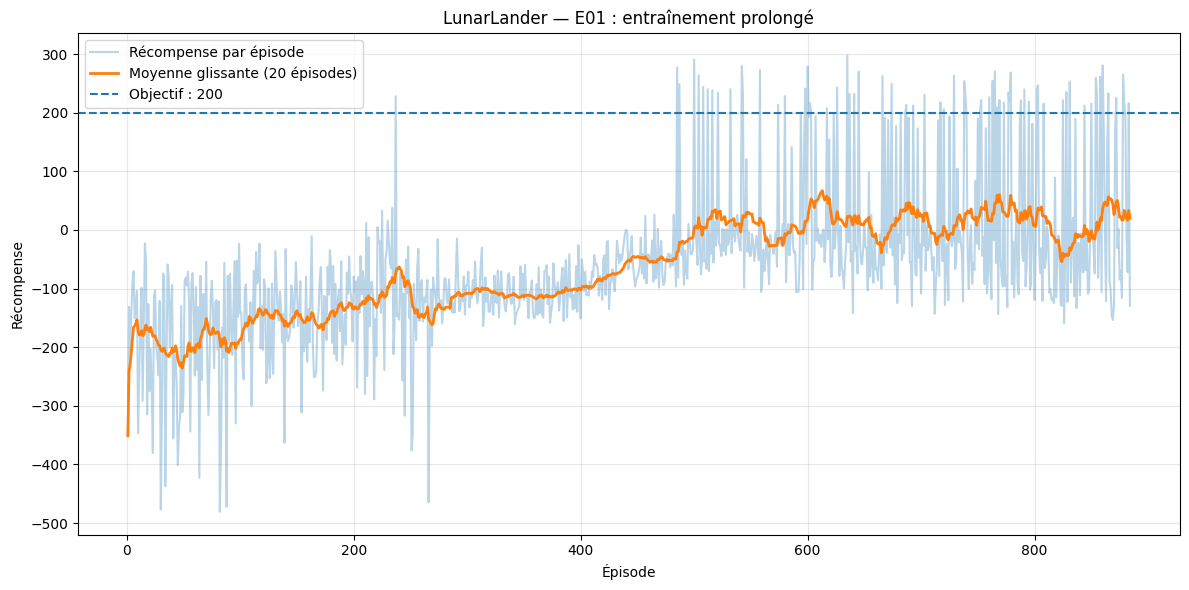


=== E01 terminée ===
Épisodes enregistrés : 884
Dernière récompense : -129.822362
Modèle : /mnt/projects/vk_oc_projet11_reinforcement_learning/models/dqn_lunarlander_E01_long_training.zip
CSV : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E01_training.csv
Graphique : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/figures/dqn_lunarlander_E01_learning_curve.png


In [23]:
# Expérience E01 : entraîner et enregistrer les récompenses 

import pandas as pd
import matplotlib.pyplot as plt
from stable_baselines3.common.callbacks import BaseCallback

class ExperimentRewardCallback(BaseCallback):
    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.rewards = []
        self.lengths = []

    def _on_step(self):
        for info in self.locals.get("infos", []):
            if "episode" in info:
                self.rewards.append(float(info["episode"]["r"]))
                self.lengths.append(int(info["episode"]["l"]))
        return True


TIMESTEPS_E01 = 500_000
callback_e01 = ExperimentRewardCallback()

model_e01.learn(
    total_timesteps=TIMESTEPS_E01,
    tb_log_name=EXP_ID,
    callback=callback_e01,
    reset_num_timesteps=True,
)

# Sauvegarder le modèle entraîné
MODEL_E01_PATH = MODELS_DIR / "dqn_lunarlander_E01_long_training"
model_e01.save(str(MODEL_E01_PATH))

# Sauvegarder les métriques d'entraînement
rewards_e01 = np.asarray(callback_e01.rewards, dtype=float)
lengths_e01 = np.asarray(callback_e01.lengths, dtype=int)

df_e01 = pd.DataFrame({
    "episode": np.arange(1, len(rewards_e01) + 1),
    "reward": rewards_e01,
    "episode_length": lengths_e01,
})

df_e01["rolling_mean_20"] = (
    df_e01["reward"].rolling(20, min_periods=1).mean()
)

CSV_E01_PATH = METRICS_DIR / "dqn_lunarlander_E01_training.csv"
df_e01.to_csv(CSV_E01_PATH, index=False)

# Tracer la courbe d'apprentissage
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    df_e01["episode"],
    df_e01["reward"],
    alpha=0.30,
    label="Récompense par épisode",
)
ax.plot(
    df_e01["episode"],
    df_e01["rolling_mean_20"],
    linewidth=2,
    label="Moyenne glissante (20 épisodes)",
)
ax.axhline(200, linestyle="--", label="Objectif : 200")
ax.set_title("LunarLander — E01 : entraînement prolongé")
ax.set_xlabel("Épisode")
ax.set_ylabel("Récompense")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

FIG_E01_PATH = FIGURES_DIR / "dqn_lunarlander_E01_learning_curve.png"
fig.savefig(FIG_E01_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("\n=== E01 terminée ===")
print("Épisodes enregistrés :", len(rewards_e01))
print("Dernière récompense :", rewards_e01[-1] if len(rewards_e01) else "Aucun épisode")
print("Modèle :", str(MODEL_E01_PATH) + ".zip")
print("CSV :", CSV_E01_PATH)
print("Graphique :", FIG_E01_PATH)


### Première lecture des résultats

- **Entraînement :** environ 500 000 interactions.
- **Épisodes enregistrés :** 884.
- **Récompense moyenne récente (`ep_rew_mean`) :** autour de 10.
- **Dernière récompense d’épisode :** −129,82.
- **Exploration :** 5 % (`exploration_rate = 0.05`).

La récompense moyenne récente est meilleure que celle du modèle de référence pendant son entraînement (environ −25,6), mais cela ne suffit pas à conclure que le modèle E01 est meilleur. La dernière récompense, elle, varie fortement d’un épisode à l’autre.

La prochaine étape est donc une évaluation équitable sur les mêmes 100 graines que le modèle de référence, sans exploration aléatoire, afin de comparer les récompenses moyennes et leur dispersion.

In [24]:
# E01 : évaluer sur 100 épisodes

from stable_baselines3 import DQN
import numpy as np
import pandas as pd
import gymnasium as gym

# Paramètres identiques à l'évaluation du modèle de référence
EVAL_SEED = 2026
N_EVAL_EPISODES = 100

# Charger le modèle E01 sauvegardé
eval_model_e01 = DQN.load(str(MODEL_E01_PATH))
env_eval_e01 = gym.make("LunarLander-v3")

rewards_e01_eval = []
lengths_e01_eval = []

for episode in range(N_EVAL_EPISODES):
    obs, info = env_eval_e01.reset(seed=EVAL_SEED + episode)
    episode_reward = 0.0
    episode_length = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = eval_model_e01.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env_eval_e01.step(
            int(action)
        )
        episode_reward += float(reward)
        episode_length += 1

    rewards_e01_eval.append(episode_reward)
    lengths_e01_eval.append(episode_length)

env_eval_e01.close()

# Calcul des indicateurs
e01_mean_100 = float(np.mean(rewards_e01_eval))
e01_std_100 = float(np.std(rewards_e01_eval, ddof=1))
e01_mean_length_100 = float(np.mean(lengths_e01_eval))

print("=== Évaluation E01 — 100 épisodes ===")
print(f"Récompense moyenne : {e01_mean_100:.2f}")
print(f"Écart-type :         {e01_std_100:.2f}")
print(f"Durée moyenne :      {e01_mean_length_100:.1f} étapes")
print(f"Objectif moyen ≥ 200 : {e01_mean_100 >= 200}")

# Sauvegarder les résultats détaillés
df_e01_eval = pd.DataFrame({
    "episode": range(1, N_EVAL_EPISODES + 1),
    "seed": range(EVAL_SEED, EVAL_SEED + N_EVAL_EPISODES),
    "reward": rewards_e01_eval,
    "episode_length": lengths_e01_eval,
})

EVAL_E01_CSV = METRICS_DIR / "dqn_lunarlander_E01_eval_100.csv"
df_e01_eval.to_csv(EVAL_E01_CSV, index=False)

# Ajouter ou actualiser l'expérience dans le registre
experiment_row = {
    "experiment_id": "E01_long_training",
    "description": "DQN entraîné sur 500 000 interactions",
    "seed": 42,
    "total_timesteps": 500_000,
    "learning_rate": 0.0001,
    "gamma": 0.99,
    "batch_size": 32,
    "mean_reward_100": e01_mean_100,
    "std_reward_100": e01_std_100,
    "model_path": str(MODEL_E01_PATH) + ".zip",
    "notes": "Évaluation déterministe sur les graines 2026 à 2125",
}

if EXPERIMENTS_CSV.exists():
    df_experiments = pd.read_csv(EXPERIMENTS_CSV)
else:
    df_experiments = pd.DataFrame()

df_experiments = df_experiments[
    df_experiments["experiment_id"] != "E01_long_training"
] if "experiment_id" in df_experiments.columns else df_experiments

df_experiments = pd.concat(
    [df_experiments, pd.DataFrame([experiment_row])],
    ignore_index=True
)
df_experiments.to_csv(EXPERIMENTS_CSV, index=False)

print(f"\nRésultats détaillés : {EVAL_E01_CSV}")
print(f"Registre des expériences : {EXPERIMENTS_CSV}")


=== Évaluation E01 — 100 épisodes ===
Récompense moyenne : -14.17
Écart-type :         139.49
Durée moyenne :      646.0 étapes
Objectif moyen ≥ 200 : False

Résultats détaillés : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E01_eval_100.csv
Registre des expériences : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/lunarlander_experiments.csv


Augmenter la durée d’entraînement de 100 000 à 500 000 interactions n’a pas suffi à apprendre un bon atterrissage. On a progressé sur la récompense moyenne par rapport à la référence, mais l’objectif reste loin d’être atteint.

#### 1. Comparaison des expériences

| Indicateur | Référence | E01 — 500k |
|---|---:|---:|
| Récompense moyenne sur 100 épisodes | −110,09 | −14,17 |
| Écart-type | 55,33 | 139,49 |
| Durée moyenne | 987 | 646 |
| Objectif moyen ≥ 200 | Non | Non |

E01 obtient une meilleure moyenne, mais son écart-type élevé indique que ses résultats restent très irréguliers. La durée moyenne plus courte peut indiquer que l’agent termine davantage d’épisodes, mais elle ne prouve pas à elle seule qu’il atterrit correctement.

#### Stratégie pour l’étape 2

Je te propose une démarche expérimentale rigoureuse : une seule modification à la fois, avec les mêmes 100 graines pour chaque évaluation.

#### E02 — Tester le taux d’apprentissage

Passer de `0.0001` à `0.0003`, en conservant les autres paramètres et le budget de 500 000 interactions.

**Hypothèse :** des mises à jour plus importantes pourraient accélérer l’apprentissage. Le risque est de rendre celui-ci plus instable.

#### E03 — Ajuster le taux d’apprentissage selon E02

Si E02 est meilleur, poursuivre dans cette direction ; sinon, tester une valeur plus faible, par exemple `0.00005`.

#### E04 — Tester la taille du batch

Comparer, par exemple, `32` à `64`, en conservant le meilleur taux d’apprentissage identifié.

#### E05 — Ajuster le facteur d’actualisation

Si nécessaire, tester `gamma = 0.995` au lieu de `0.99` pour donner davantage de poids aux récompenses futures.

Ces hypothèses sont à tester, pas des améliorations garanties. Si ces essais ne suffisent pas, nous examinerons ensuite la fréquence d’apprentissage, la taille du buffer et la stratégie d’exploration.

In [25]:
# E02: création du modèle

from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
import gymnasium as gym

EXP_ID = "E02_learning_rate_0003"
TRAIN_SEED = 42

env_e02 = Monitor(gym.make("LunarLander-v3"))

model_e02 = DQN(
    policy="MlpPolicy",
    env=env_e02,
    verbose=1,
    tensorboard_log=str(LOGS_DIR),
    seed=TRAIN_SEED,
    learning_rate=0.0003,  # Seul paramètre modifié
    gamma=0.99,
    batch_size=32,
)

print("Expérience :", EXP_ID)
print("Taux d'apprentissage :", model_e02.learning_rate)
print("Gamma :", model_e02.gamma)
print("Batch size :", model_e02.batch_size)
print("Budget prévu : 500 000 interactions")


Using cuda device
Wrapping the env in a DummyVecEnv.
Expérience : E02_learning_rate_0003
Taux d'apprentissage : 0.0003
Gamma : 0.99
Batch size : 32
Budget prévu : 500 000 interactions


Logging to /mnt/projects/vk_oc_projet11_reinforcement_learning/logs/lunarlander/E02_learning_rate_0003_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 94.5     |
|    ep_rew_mean      | -208     |
|    exploration_rate | 0.993    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 3965     |
|    time_elapsed     | 0        |
|    total_timesteps  | 378      |
| train/              |          |
|    learning_rate    | 0.0003   |
|    loss             | 4.9      |
|    n_updates        | 69       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 87.4     |
|    ep_rew_mean      | -159     |
|    exploration_rate | 0.987    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 3822     |
|    time_elapsed     | 0        |
|    total_timesteps  | 699      |
| train/            

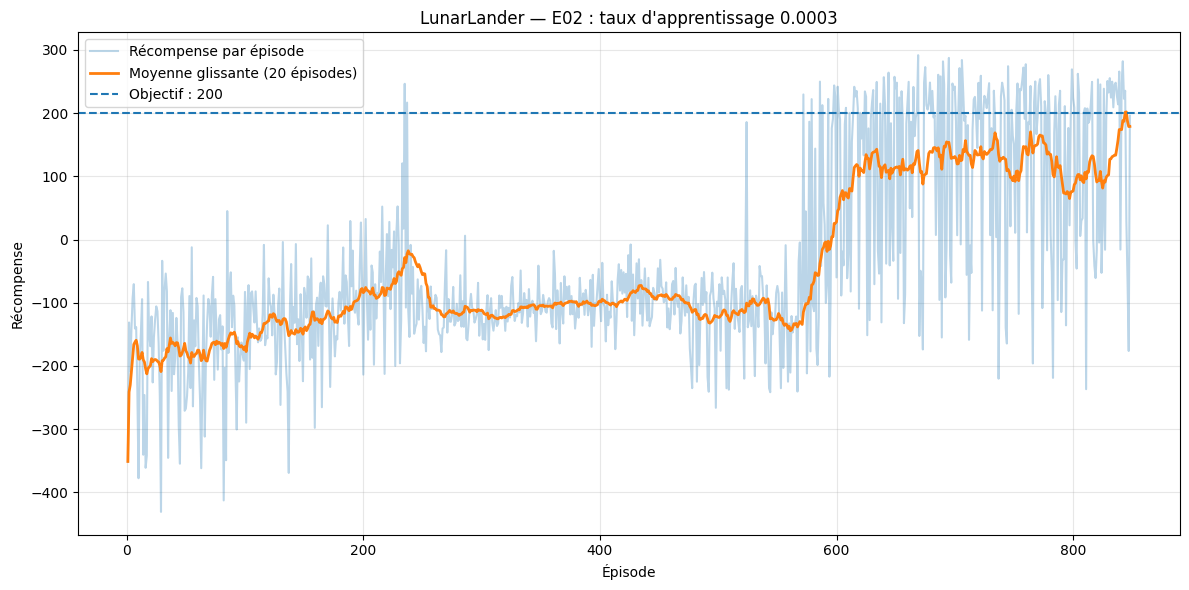

=== E02 terminée ===
Épisodes enregistrés : 848
Dernière récompense : 195.79
Moyenne des 20 derniers épisodes : 179.02
Modèle : /mnt/projects/vk_oc_projet11_reinforcement_learning/models/dqn_lunarlander_E02_learning_rate_0003.zip
CSV : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E02_training.csv
Graphique : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/figures/dqn_lunarlander_E02_learning_curve.png


In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stable_baselines3.common.callbacks import BaseCallback

# Collecte des récompenses et durées de chaque épisode
class ExperimentRewardCallback(BaseCallback):
    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.rewards = []
        self.lengths = []

    def _on_step(self):
        for info in self.locals.get("infos", []):
            if "episode" in info:
                self.rewards.append(float(info["episode"]["r"]))
                self.lengths.append(int(info["episode"]["l"]))
        return True


# Budget d'entraînement
TIMESTEPS_E02 = 500_000
callback_e02 = ExperimentRewardCallback()

# Entraînement
model_e02.learn(
    total_timesteps=TIMESTEPS_E02,
    tb_log_name=EXP_ID,
    callback=callback_e02,
    reset_num_timesteps=True,
)

# Sauvegarde du modèle
MODEL_E02_PATH = MODELS_DIR / "dqn_lunarlander_E02_learning_rate_0003"
model_e02.save(str(MODEL_E02_PATH))

# Enregistrer les récompenses et durées
rewards_e02 = np.asarray(callback_e02.rewards, dtype=float)
lengths_e02 = np.asarray(callback_e02.lengths, dtype=int)

df_e02 = pd.DataFrame({
    "episode": np.arange(1, len(rewards_e02) + 1),
    "reward": rewards_e02,
    "episode_length": lengths_e02,
})
df_e02["rolling_mean_20"] = (
    df_e02["reward"].rolling(20, min_periods=1).mean()
)

CSV_E02_PATH = METRICS_DIR / "dqn_lunarlander_E02_training.csv"
df_e02.to_csv(CSV_E02_PATH, index=False)

# Tracer la courbe d'apprentissage
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    df_e02["episode"],
    df_e02["reward"],
    alpha=0.30,
    label="Récompense par épisode",
)
ax.plot(
    df_e02["episode"],
    df_e02["rolling_mean_20"],
    linewidth=2,
    label="Moyenne glissante (20 épisodes)",
)
ax.axhline(
    200,
    linestyle="--",
    label="Objectif : 200",
)
ax.set_title("LunarLander — E02 : taux d'apprentissage 0.0003")
ax.set_xlabel("Épisode")
ax.set_ylabel("Récompense")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

FIG_E02_PATH = (
    FIGURES_DIR / "dqn_lunarlander_E02_learning_curve.png"
)
fig.savefig(FIG_E02_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("=== E02 terminée ===")
print(f"Épisodes enregistrés : {len(rewards_e02)}")
if len(rewards_e02) > 0:
    print(f"Dernière récompense : {rewards_e02[-1]:.2f}")
    print(
        "Moyenne des 20 derniers épisodes : "
        f"{df_e02['reward'].tail(20).mean():.2f}"
    )
print(f"Modèle : {MODEL_E02_PATH}.zip")
print(f"CSV : {CSV_E02_PATH}")
print(f"Graphique : {FIG_E02_PATH}")


#### Comparaison des expériences

| Indicateur | E01 — taux 0,0001 | E02 — taux 0,0003 |
|---|---:|---:|
| Interactions prévues | 500 000 | 500 000 |
| Moyenne d’entraînement récente | Environ 10 | 179,02 sur les 20 derniers épisodes |
| Dernière récompense | — | 195,79 |
| Moyenne d’évaluation sur 100 épisodes | −14,17 | À mesurer |
| Objectif ≥ 200 | Non atteint | À confirmer |

Le taux d’apprentissage `0.0003` semble donc beaucoup plus prometteur. Attention toutefois : la dernière récompense de 195,79 ne signifie pas que le modèle obtient une moyenne de 200.

In [27]:
# E02: évaluation sur 100 épisodes

from stable_baselines3 import DQN
import numpy as np
import pandas as pd
import gymnasium as gym

# Paramètres communs à toutes les évaluations
EVAL_SEED = 2026
N_EVAL_EPISODES = 100

# Charger E02
eval_model_e02 = DQN.load(str(MODEL_E02_PATH))
env_eval_e02 = gym.make("LunarLander-v3")

rewards_e02_eval = []
lengths_e02_eval = []

for episode in range(N_EVAL_EPISODES):
    obs, info = env_eval_e02.reset(seed=EVAL_SEED + episode)

    episode_reward = 0.0
    episode_length = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = eval_model_e02.predict(
            obs,
            deterministic=True
        )

        obs, reward, terminated, truncated, info = (
            env_eval_e02.step(int(action))
        )

        episode_reward += float(reward)
        episode_length += 1

    rewards_e02_eval.append(episode_reward)
    lengths_e02_eval.append(episode_length)

env_eval_e02.close()

# Calcul des indicateurs
e02_mean_100 = float(np.mean(rewards_e02_eval))
e02_std_100 = float(np.std(rewards_e02_eval, ddof=1))
e02_mean_length_100 = float(np.mean(lengths_e02_eval))

print("=== Évaluation E02 — 100 épisodes ===")
print(f"Récompense moyenne : {e02_mean_100:.2f}")
print(f"Écart-type :         {e02_std_100:.2f}")
print(f"Durée moyenne :      {e02_mean_length_100:.1f} étapes")
print(f"Objectif moyen >= 200 : {e02_mean_100 >= 200}")

# Sauvegarder les résultats détaillés
df_e02_eval = pd.DataFrame({
    "episode": range(1, N_EVAL_EPISODES + 1),
    "seed": range(EVAL_SEED, EVAL_SEED + N_EVAL_EPISODES),
    "reward": rewards_e02_eval,
    "episode_length": lengths_e02_eval,
})

EVAL_E02_CSV = (
    METRICS_DIR / "dqn_lunarlander_E02_eval_100.csv"
)
df_e02_eval.to_csv(EVAL_E02_CSV, index=False)

print(f"\nRésultats détaillés : {EVAL_E02_CSV}")


=== Évaluation E02 — 100 épisodes ===
Récompense moyenne : 129.26
Écart-type :         120.16
Durée moyenne :      597.1 étapes
Objectif moyen >= 200 : False

Résultats détaillés : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E02_eval_100.csv


### Bilan : où en sommes-nous ?

| Expérience | Paramètres principaux | Moyenne sur 100 épisodes | Écart-type |
|---|---|---:|---:|
| Référence | DQN par défaut, 100 000 interactions | −110,09 | 55,33 |
| E01 | Taux `0.0001`, 500 000 interactions | −14,17 | 139,49 |
| E02 | Taux `0.0003`, 500 000 interactions | 129,26 | 120,16 |
| Objectif | — | ≥ 200 | À réduire si possible |

E02 est notre meilleur candidat jusqu’à présent. Il améliore la moyenne de 143,43 points par rapport à E01, mais reste à 70,74 points de l’objectif.

La différence entre sa moyenne d’entraînement récente (179,02 sur les 20 derniers épisodes) et sa moyenne d’évaluation (129,26) montre qu’il ne faut pas choisir un modèle uniquement sur ses dernières récompenses d’entraînement.

#### Stratégie mise à jour

Le plan initial est conservé avec pour chaque expérience, le changement d'un seul paramètre. Nous évaluons sur les mêmes graines 2026 à 2125 et nous conservons le meilleur modèle.

| Expérience | Modification par rapport au meilleur candidat | Décision |
|---|---|---|
| E03 | Taux d’apprentissage `0.0005` | Tester une valeur plus élevée que `0.0003` |
| E04 | Batch size `64` | À tester si E03 n’atteint pas l’objectif |
| E05 | Gamma `0.995` | À tester ensuite si nécessaire |

Pourquoi ajuster E03 ? Le taux `0.0003` a nettement amélioré les résultats par rapport à `0.0001`. Tester `0.0005` permet de vérifier si une hausse supplémentaire aide encore l’apprentissage. Ce n’est pas garanti : un taux trop élevé peut aussi déstabiliser les mises à jour.

Ne pas passer tout de suite à `0.00005` : cette valeur est plus faible que celle d’E01, qui a obtenu une moyenne négative. Nous pourrons y revenir si les prochains essais montrent que le taux élevé est instable.

#### E03 — Tester un taux d’apprentissage de `0.0005`

Nous allons entraîner un nouveau modèle depuis zéro, sans reprendre les poids d’E02. Cela permet de comparer les hyperparamètres dans des conditions similaires.

Pour cette expérience, nous conservons :

- **Budget :** 500 000 interactions.
- **Gamma :** `0.99`.
- **Batch size :** `32`.
- **Graine d’entraînement :** `42`.
- **Taux d’apprentissage :** `0.0005` au lieu de `0.0003`.

In [28]:
# E03: création du modèle

from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
import gymnasium as gym

EXP_ID = "E03_learning_rate_0005"
TRAIN_SEED = 42

env_e03 = Monitor(gym.make("LunarLander-v3"))
env_e03.reset(seed=TRAIN_SEED)

model_e03 = DQN(
    policy="MlpPolicy",
    env=env_e03,
    verbose=1,
    tensorboard_log=str(LOGS_DIR),
    seed=TRAIN_SEED,
    learning_rate=0.0005,
    gamma=0.99,
    batch_size=32,
)

print("Expérience :", EXP_ID)
print("Taux d'apprentissage :", 0.0005)
print("Gamma :", 0.99)
print("Batch size :", 32)
print("Budget prévu :", 500_000, "interactions")


Using cuda device
Wrapping the env in a DummyVecEnv.
Expérience : E03_learning_rate_0005
Taux d'apprentissage : 0.0005
Gamma : 0.99
Batch size : 32
Budget prévu : 500000 interactions


Logging to /mnt/projects/vk_oc_projet11_reinforcement_learning/logs/lunarlander/E03_learning_rate_0005_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 94.5     |
|    ep_rew_mean      | -208     |
|    exploration_rate | 0.993    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 3883     |
|    time_elapsed     | 0        |
|    total_timesteps  | 378      |
| train/              |          |
|    learning_rate    | 0.0005   |
|    loss             | 4.77     |
|    n_updates        | 69       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 87.4     |
|    ep_rew_mean      | -159     |
|    exploration_rate | 0.987    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 3753     |
|    time_elapsed     | 0        |
|    total_timesteps  | 699      |
| train/            

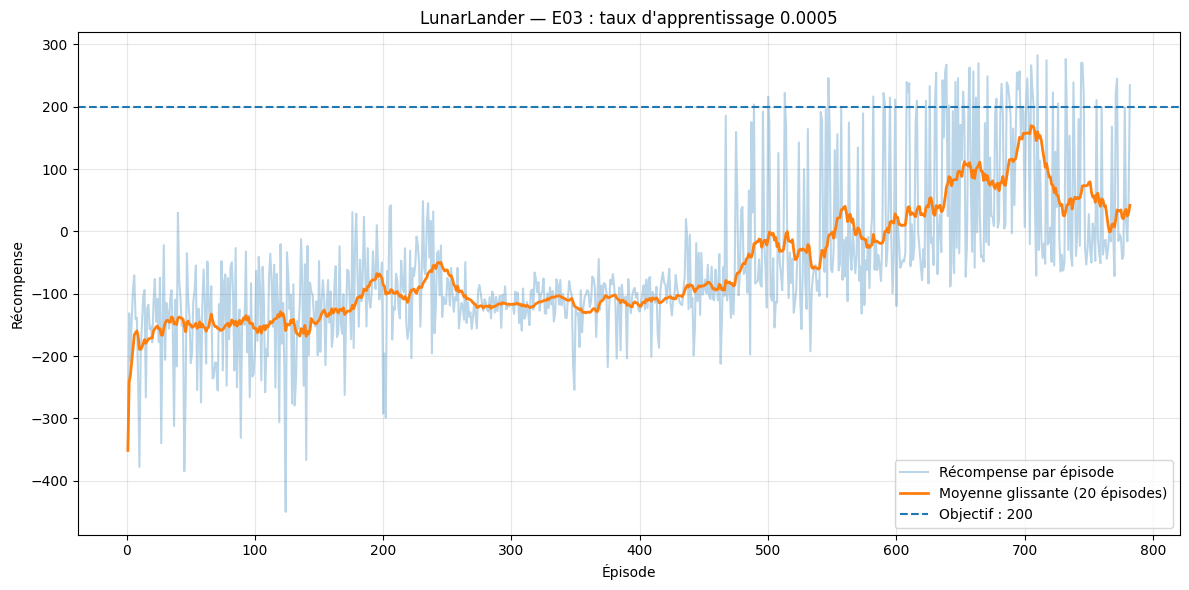

=== E03 terminée ===
Épisodes enregistrés : 782
Dernière récompense : 234.51
Moyenne des 20 derniers épisodes : 41.94
Modèle : /mnt/projects/vk_oc_projet11_reinforcement_learning/models/dqn_lunarlander_E03_learning_rate_0005.zip
CSV : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E03_training.csv
Graphique : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/figures/dqn_lunarlander_E03_learning_curve.png


In [29]:
# E03 : entraînement et sauvegarde

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stable_baselines3.common.callbacks import BaseCallback

class ExperimentRewardCallback(BaseCallback):
    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.rewards = []
        self.lengths = []

    def _on_step(self):
        for info in self.locals.get("infos", []):
            if "episode" in info:
                self.rewards.append(float(info["episode"]["r"]))
                self.lengths.append(int(info["episode"]["l"]))
        return True


TIMESTEPS_E03 = 500_000
callback_e03 = ExperimentRewardCallback()

model_e03.learn(
    total_timesteps=TIMESTEPS_E03,
    tb_log_name=EXP_ID,
    callback=callback_e03,
    reset_num_timesteps=True,
)

# Sauvegarder le modèle
MODEL_E03_PATH = MODELS_DIR / "dqn_lunarlander_E03_learning_rate_0005"
model_e03.save(str(MODEL_E03_PATH))

# Enregistrer les récompenses d'entraînement
rewards_e03 = np.asarray(callback_e03.rewards, dtype=float)
lengths_e03 = np.asarray(callback_e03.lengths, dtype=int)

df_e03 = pd.DataFrame({
    "episode": np.arange(1, len(rewards_e03) + 1),
    "reward": rewards_e03,
    "episode_length": lengths_e03,
})
df_e03["rolling_mean_20"] = (
    df_e03["reward"].rolling(20, min_periods=1).mean()
)

CSV_E03_PATH = METRICS_DIR / "dqn_lunarlander_E03_training.csv"
df_e03.to_csv(CSV_E03_PATH, index=False)

# Tracer la courbe d'apprentissage
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    df_e03["episode"],
    df_e03["reward"],
    alpha=0.30,
    label="Récompense par épisode",
)
ax.plot(
    df_e03["episode"],
    df_e03["rolling_mean_20"],
    linewidth=2,
    label="Moyenne glissante (20 épisodes)",
)
ax.axhline(200, linestyle="--", label="Objectif : 200")
ax.set_title("LunarLander — E03 : taux d'apprentissage 0.0005")
ax.set_xlabel("Épisode")
ax.set_ylabel("Récompense")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

FIG_E03_PATH = FIGURES_DIR / "dqn_lunarlander_E03_learning_curve.png"
fig.savefig(FIG_E03_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("=== E03 terminée ===")
print(f"Épisodes enregistrés : {len(rewards_e03)}")

if len(rewards_e03) > 0:
    print(f"Dernière récompense : {rewards_e03[-1]:.2f}")
    print(
        "Moyenne des 20 derniers épisodes : "
        f"{df_e03['reward'].tail(20).mean():.2f}"
    )

print(f"Modèle : {MODEL_E03_PATH}.zip")
print(f"CSV : {CSV_E03_PATH}")
print(f"Graphique : {FIG_E03_PATH}")



E03 est terminé, mais les résultats d’entraînement sont moins encourageants que ceux d’E02 : la moyenne glissante des 20 derniers épisodes est de 41,94, contre 179,02 pour E02. La dernière récompense de 234,51 est intéressante, mais elle ne suffit pas à juger le modèle.
Nous devons maintenant évaluer E03 sur les mêmes 100 graines, puis choisir la suite à partir de la moyenne mesurée.

In [30]:
# E03 : évaluation sur 100 épisodes

from stable_baselines3 import DQN
import numpy as np
import pandas as pd
import gymnasium as gym

EVAL_SEED = 2026
N_EVAL_EPISODES = 100

# Charger le modèle E03
eval_model_e03 = DQN.load(str(MODEL_E03_PATH))
env_eval_e03 = gym.make("LunarLander-v3")

rewards_e03_eval = []
lengths_e03_eval = []

for episode in range(N_EVAL_EPISODES):
    obs, info = env_eval_e03.reset(seed=EVAL_SEED + episode)

    episode_reward = 0.0
    episode_length = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = eval_model_e03.predict(
            obs,
            deterministic=True
        )

        obs, reward, terminated, truncated, info = (
            env_eval_e03.step(int(action))
        )

        episode_reward += float(reward)
        episode_length += 1

    rewards_e03_eval.append(episode_reward)
    lengths_e03_eval.append(episode_length)

env_eval_e03.close()

# Calcul des indicateurs
e03_mean_100 = float(np.mean(rewards_e03_eval))
e03_std_100 = float(np.std(rewards_e03_eval, ddof=1))
e03_mean_length_100 = float(np.mean(lengths_e03_eval))

print("=== Évaluation E03 — 100 épisodes ===")
print(f"Récompense moyenne : {e03_mean_100:.2f}")
print(f"Écart-type :         {e03_std_100:.2f}")
print(f"Durée moyenne :      {e03_mean_length_100:.1f} étapes")
print(f"Objectif moyen >= 200 : {e03_mean_100 >= 200}")

# Sauvegarder les résultats détaillés
df_e03_eval = pd.DataFrame({
    "episode": range(1, N_EVAL_EPISODES + 1),
    "seed": range(EVAL_SEED, EVAL_SEED + N_EVAL_EPISODES),
    "reward": rewards_e03_eval,
    "episode_length": lengths_e03_eval,
})

EVAL_E03_CSV = METRICS_DIR / "dqn_lunarlander_E03_eval_100.csv"
df_e03_eval.to_csv(EVAL_E03_CSV, index=False)

print(f"\nRésultats détaillés : {EVAL_E03_CSV}")



=== Évaluation E03 — 100 épisodes ===
Récompense moyenne : 14.62
Écart-type :         68.47
Durée moyenne :      923.9 étapes
Objectif moyen >= 200 : False

Résultats détaillés : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E03_eval_100.csv


#### Notre décision après E03

- Si E03 dépasse E02 en évaluation, nous analyserons sa stabilité.
- Si E03 fait moins bien qu’E02, nous garderons E02 comme meilleur candidat et passerons à E04 : batch size de 64, avec un taux d’apprentissage de `0.0003`.
- Si E03 atteint une moyenne d’au moins 200, nous vérifierons la stabilité avant de considérer l’objectif atteint.

Nous conservons E02 comme meilleur modèle et nous passons à E04.

E03 confirme qu’un taux d’apprentissage plus élevé n’est pas forcément meilleur. Malgré une dernière récompense d’entraînement de 234,51, sa moyenne d’évaluation n’est que de 14,62. La durée moyenne de 923,9 étapes suggère que le modèle passe souvent beaucoup de temps en vol sans réussir un atterrissage suffisamment performant.

#### Bilan des expériences

| Expérience | Taux d’apprentissage | Batch size | Moyenne sur 100 épisodes |
|---|---:|---:|---:|
| E01 | 0,0001 | 32 | −14,17 |
| E02 | 0,0003 | 32 | 129,26 |
| E03 | 0,0005 | 32 | 14,62 |
| Objectif | — | — | ≥ 200 |

E02 reste notre référence de travail. Nous sommes à 70,74 points de l’objectif.

#### E04 — Tester un batch size de 64

Nous suivons maintenant le plan prévu : conserver le taux d’apprentissage de `0.0003` et augmenter uniquement le batch size de `32` à `64`.

Nous gardons également :

- 500 000 interactions ;
- `gamma = 0.99` ;
- la graine d’entraînement `42` ;
- les mêmes 100 graines d’évaluation, de 2026 à 2125.

In [31]:
# E04: création du modèle

from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
import gymnasium as gym

EXP_ID = "E04_batch_size_64"
TRAIN_SEED = 42

env_e04 = Monitor(gym.make("LunarLander-v3"))
env_e04.reset(seed=TRAIN_SEED)

model_e04 = DQN(
    policy="MlpPolicy",
    env=env_e04,
    verbose=1,
    tensorboard_log=str(LOGS_DIR),
    seed=TRAIN_SEED,
    learning_rate=0.0003,
    gamma=0.99,
    batch_size=64,
)

print("Expérience :", EXP_ID)
print("Taux d'apprentissage :", 0.0003)
print("Gamma :", 0.99)
print("Batch size :", 64)
print("Budget prévu :", 500_000, "interactions")


Using cuda device
Wrapping the env in a DummyVecEnv.
Expérience : E04_batch_size_64
Taux d'apprentissage : 0.0003
Gamma : 0.99
Batch size : 64
Budget prévu : 500000 interactions


Logging to /mnt/projects/vk_oc_projet11_reinforcement_learning/logs/lunarlander/E04_batch_size_64_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 94.5     |
|    ep_rew_mean      | -208     |
|    exploration_rate | 0.993    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 3813     |
|    time_elapsed     | 0        |
|    total_timesteps  | 378      |
| train/              |          |
|    learning_rate    | 0.0003   |
|    loss             | 2.97     |
|    n_updates        | 69       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 96.4     |
|    ep_rew_mean      | -210     |
|    exploration_rate | 0.985    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 3725     |
|    time_elapsed     | 0        |
|    total_timesteps  | 771      |
| train/              |  

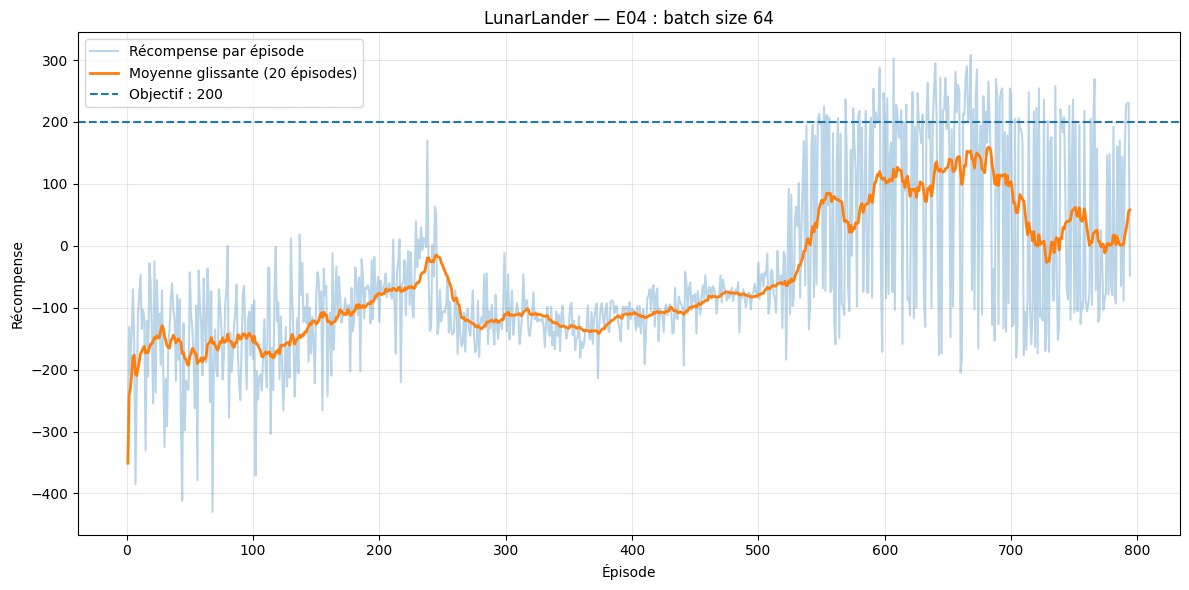

=== E04 terminée ===
Épisodes enregistrés : 794
Dernière récompense : -48.34
Moyenne des 20 derniers épisodes : 57.86
Modèle : /mnt/projects/vk_oc_projet11_reinforcement_learning/models/dqn_lunarlander_E04_batch_size_64.zip
CSV : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E04_training.csv
Graphique : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/figures/dqn_lunarlander_E04_learning_curve.png


In [32]:
# E04 : entrainement et sauvegarde

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stable_baselines3.common.callbacks import BaseCallback

class ExperimentRewardCallback(BaseCallback):
    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.rewards = []
        self.lengths = []

    def _on_step(self):
        for info in self.locals.get("infos", []):
            if "episode" in info:
                self.rewards.append(float(info["episode"]["r"]))
                self.lengths.append(int(info["episode"]["l"]))
        return True


TIMESTEPS_E04 = 500_000
callback_e04 = ExperimentRewardCallback()

model_e04.learn(
    total_timesteps=TIMESTEPS_E04,
    tb_log_name=EXP_ID,
    callback=callback_e04,
    reset_num_timesteps=True,
)

# Sauvegarder le modèle
MODEL_E04_PATH = MODELS_DIR / "dqn_lunarlander_E04_batch_size_64"
model_e04.save(str(MODEL_E04_PATH))

# Sauvegarder les récompenses d'entraînement
rewards_e04 = np.asarray(callback_e04.rewards, dtype=float)
lengths_e04 = np.asarray(callback_e04.lengths, dtype=int)

df_e04 = pd.DataFrame({
    "episode": np.arange(1, len(rewards_e04) + 1),
    "reward": rewards_e04,
    "episode_length": lengths_e04,
})
df_e04["rolling_mean_20"] = (
    df_e04["reward"].rolling(20, min_periods=1).mean()
)

CSV_E04_PATH = METRICS_DIR / "dqn_lunarlander_E04_training.csv"
df_e04.to_csv(CSV_E04_PATH, index=False)

# Courbe d'apprentissage
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    df_e04["episode"],
    df_e04["reward"],
    alpha=0.30,
    label="Récompense par épisode",
)
ax.plot(
    df_e04["episode"],
    df_e04["rolling_mean_20"],
    linewidth=2,
    label="Moyenne glissante (20 épisodes)",
)
ax.axhline(200, linestyle="--", label="Objectif : 200")
ax.set_title("LunarLander — E04 : batch size 64")
ax.set_xlabel("Épisode")
ax.set_ylabel("Récompense")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

FIG_E04_PATH = FIGURES_DIR / "dqn_lunarlander_E04_learning_curve.png"
fig.savefig(FIG_E04_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("=== E04 terminée ===")
print(f"Épisodes enregistrés : {len(rewards_e04)}")

if len(rewards_e04) > 0:
    print(f"Dernière récompense : {rewards_e04[-1]:.2f}")
    print(
        "Moyenne des 20 derniers épisodes : "
        f"{df_e04['reward'].tail(20).mean():.2f}"
    )

print(f"Modèle : {MODEL_E04_PATH}.zip")
print(f"CSV : {CSV_E04_PATH}")
print(f"Graphique : {FIG_E04_PATH}")



In [33]:

from stable_baselines3 import DQN
import numpy as np
import pandas as pd
import gymnasium as gym

EVAL_SEED = 2026
N_EVAL_EPISODES = 100

eval_model_e04 = DQN.load(str(MODEL_E04_PATH))
env_eval_e04 = gym.make("LunarLander-v3")

rewards_e04_eval = []
lengths_e04_eval = []

for episode in range(N_EVAL_EPISODES):
    obs, info = env_eval_e04.reset(seed=EVAL_SEED + episode)
    episode_reward = 0.0
    episode_length = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = eval_model_e04.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env_eval_e04.step(
            int(action)
        )
        episode_reward += float(reward)
        episode_length += 1

    rewards_e04_eval.append(episode_reward)
    lengths_e04_eval.append(episode_length)

env_eval_e04.close()

e04_mean_100 = float(np.mean(rewards_e04_eval))
e04_std_100 = float(np.std(rewards_e04_eval, ddof=1))
e04_mean_length_100 = float(np.mean(lengths_e04_eval))

print("=== Évaluation E04 — 100 épisodes ===")
print(f"Récompense moyenne : {e04_mean_100:.2f}")
print(f"Écart-type :         {e04_std_100:.2f}")
print(f"Durée moyenne :      {e04_mean_length_100:.1f} étapes")
print(f"Objectif moyen >= 200 : {e04_mean_100 >= 200}")

df_e04_eval = pd.DataFrame({
    "episode": range(1, N_EVAL_EPISODES + 1),
    "seed": range(EVAL_SEED, EVAL_SEED + N_EVAL_EPISODES),
    "reward": rewards_e04_eval,
    "episode_length": lengths_e04_eval,
})

EVAL_E04_CSV = METRICS_DIR / "dqn_lunarlander_E04_eval_100.csv"
df_e04_eval.to_csv(EVAL_E04_CSV, index=False)

print(f"Résultats détaillés : {EVAL_E04_CSV}")


=== Évaluation E04 — 100 épisodes ===
Récompense moyenne : -14.24
Écart-type :         114.94
Durée moyenne :      859.3 étapes
Objectif moyen >= 200 : False
Résultats détaillés : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E04_eval_100.csv


Augmenter le batch size de 32 à 64 n’a pas amélioré notre modèle. Nous pouvons donc revenir aux paramètres d’E02, qui reste le meilleur candidat.

#### Analyse comparative des résultats

| Expérience | Modification | Moyenne sur 100 épisodes | Écart-type |
|---|---|---:|---:|
| Référence | DQN par défaut | −110,09 | 55,33 |
| E01 | 500 000 interactions, taux 0,0001 | −14,17 | 139,49 |
| E02 | Taux 0,0003, batch 32 | 129,26 | 120,16 |
| E03 | Taux 0,0005 | 14,62 | 68,47 |
| E04 | Batch 64, taux 0,0003 | −14,24 | 114,94 |
| Objectif | — | ≥ 200 | À réduire si possible |

Les conclusions sont les suivantes :

- **E02 est nettement le meilleur modèle évalué à ce stade.** Il dépasse E04 de 143,50 points de récompense moyenne.
- **E03 indique qu’un taux d’apprentissage trop élevé peut dégrader les performances.**
- **E04 indique que l’augmentation du batch size n’est pas bénéfique dans les conditions testées.**
- **L’écart-type d’E02 reste élevé :** les performances sont irrégulières.
- **Aucun modèle n’a encore atteint l’objectif de 200.**

Ces expériences ne sont pas inutiles : elles permettent de justifier pourquoi nous retenons certains paramètres et en écartons d’autres.

#### Suite : E05 — augmenter gamma à 0,995

Nous poursuivons le plan initial, mais nous améliorons le suivi de l’apprentissage. Pour E05, nous conservons les paramètres d’E02 et modifions uniquement le facteur d’actualisation :

- **Taux d’apprentissage :** `0.0003`
- **Batch size :** `32`
- **Gamma :** `0.995` au lieu de `0.99`
- **Budget :** 500 000 interactions
- **Graine d’entraînement :** `42`

Un gamma plus élevé donne davantage de poids aux récompenses futures. Cela pourrait aider l’agent à mieux prendre en compte les conséquences de ses actions sur l’atterrissage, sans garantir une amélioration.

In [34]:
# E05 : création du modèle

from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import EvalCallback
import gymnasium as gym

EXP_ID = "E05_gamma_0995"
TRAIN_SEED = 42

# Environnement d'entraînement
env_e05 = Monitor(gym.make("LunarLander-v3"))
env_e05.reset(seed=TRAIN_SEED)

# Environnement distinct pour les évaluations périodiques
eval_env_e05 = Monitor(gym.make("LunarLander-v3"))

# Dossier de sauvegarde du meilleur modèle intermédiaire
BEST_E05_DIR = MODELS_DIR / "E05_best"
BEST_E05_DIR.mkdir(parents=True, exist_ok=True)

EVAL_E05_LOG_DIR = METRICS_DIR / "E05_eval_callback"
EVAL_E05_LOG_DIR.mkdir(parents=True, exist_ok=True)

# Évaluation tous les 25 000 pas, sur 10 épisodes
eval_callback_e05 = EvalCallback(
    eval_env_e05,
    best_model_save_path=str(BEST_E05_DIR),
    log_path=str(EVAL_E05_LOG_DIR),
    eval_freq=25_000,
    n_eval_episodes=10,
    deterministic=True,
    render=False,
    verbose=1,
)

# Modèle E05 : seul gamma change par rapport à E02
model_e05 = DQN(
    policy="MlpPolicy",
    env=env_e05,
    verbose=1,
    tensorboard_log=str(LOGS_DIR),
    seed=TRAIN_SEED,
    learning_rate=0.0003,
    gamma=0.995,
    batch_size=32,
)

print("Expérience :", EXP_ID)
print("Taux d'apprentissage : 0.0003")
print("Gamma : 0.995")
print("Batch size : 32")
print("Budget prévu : 500 000 interactions")
print("Évaluation intermédiaire : tous les 25 000 pas")
print("Épisodes par évaluation intermédiaire : 10")
print("Dossier du meilleur modèle :", BEST_E05_DIR)


Using cuda device
Wrapping the env in a DummyVecEnv.
Expérience : E05_gamma_0995
Taux d'apprentissage : 0.0003
Gamma : 0.995
Batch size : 32
Budget prévu : 500 000 interactions
Évaluation intermédiaire : tous les 25 000 pas
Épisodes par évaluation intermédiaire : 10
Dossier du meilleur modèle : /mnt/projects/vk_oc_projet11_reinforcement_learning/models/E05_best


In [35]:
# E05 : entraîenement
# Collecter les récompenses des épisodes pendant l'entraînement
callback_e05 = ExperimentRewardCallback()

# Entraîner le modèle et évaluer périodiquement ses performances
model_e05.learn(
    total_timesteps=500_000,
    tb_log_name=EXP_ID,
    callback=[callback_e05, eval_callback_e05],
    reset_num_timesteps=True,
)

# Sauvegarder le modèle final
FINAL_E05_PATH = MODELS_DIR / "dqn_lunarlander_E05_gamma_0995"
model_e05.save(str(FINAL_E05_PATH))

# Sauvegarder les récompenses d'entraînement
training_e05_df = pd.DataFrame({
    "episode": range(1, len(callback_e05.rewards) + 1),
    "reward": callback_e05.rewards,
    "length": callback_e05.lengths,
})

training_e05_df.to_csv(
    METRICS_DIR / "dqn_lunarlander_E05_training.csv",
    index=False,
)

print("\n=== Entraînement E05 terminé ===")
print("Épisodes terminés :", len(callback_e05.rewards))
print("Récompense des 20 derniers épisodes :",
      round(np.mean(callback_e05.rewards[-20:]), 2)
      if len(callback_e05.rewards) >= 20 else "Pas assez d'épisodes")
print("Modèle final sauvegardé :", str(FINAL_E05_PATH) + ".zip")
print("Meilleur modèle intermédiaire :", BEST_E05_DIR / "best_model.zip")
print("Historique sauvegardé :", METRICS_DIR / "dqn_lunarlander_E05_training.csv")

Logging to /mnt/projects/vk_oc_projet11_reinforcement_learning/logs/lunarlander/E05_gamma_0995_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 94.5     |
|    ep_rew_mean      | -208     |
|    exploration_rate | 0.993    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 3610     |
|    time_elapsed     | 0        |
|    total_timesteps  | 378      |
| train/              |          |
|    learning_rate    | 0.0003   |
|    loss             | 4.9      |
|    n_updates        | 69       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 87.4     |
|    ep_rew_mean      | -159     |
|    exploration_rate | 0.987    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 3442     |
|    time_elapsed     | 0        |
|    total_timesteps  | 699      |
| train/              |     

Récompense moyenne des 20 derniers épisodes d’entraînement : 187,2

- **Meilleur score moyen lors de l’évaluation intermédiaire :** 128,27 ± 136,35 sur 10 épisodes à 500 000 pas.
- **Meilleur modèle intermédiaire :** `models/E05_best/best_model.zip`

La différence entre la récompense récente d’entraînement et l’évaluation montre que les performances varient encore beaucoup. Nous allons comparer le meilleur modèle intermédiaire au modèle final sur les mêmes 100 épisodes, pour décider lequel conserver.

In [36]:
# E05: Evaluer le meilleur modèle intermédiaire
from stable_baselines3 import DQN
import gymnasium as gym
import numpy as np

BEST_E05_PATH = BEST_E05_DIR / "best_model.zip"

# Vérifier que le meilleur modèle a bien été sauvegardé
assert BEST_E05_PATH.exists(), (
    f"Fichier introuvable : {BEST_E05_PATH}"
)

best_model_e05 = DQN.load(str(BEST_E05_PATH))

eval_env = gym.make("LunarLander-v3")
rewards_best_e05 = []

for seed in range(2026, 2126):
    obs, info = eval_env.reset(seed=seed)
    episode_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = best_model_e05.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env.step(int(action))
        episode_reward += reward

    rewards_best_e05.append(episode_reward)

eval_env.close()

mean_best_e05 = float(np.mean(rewards_best_e05))
std_best_e05 = float(np.std(rewards_best_e05, ddof=1))

print("=== Évaluation E05 — meilleur modèle intermédiaire ===")
print("Nombre d'épisodes :", len(rewards_best_e05))
print(f"Récompense moyenne : {mean_best_e05:.2f}")
print(f"Écart-type : {std_best_e05:.2f}")
print("Objectif moyen >= 200 :", mean_best_e05 >= 200)

=== Évaluation E05 — meilleur modèle intermédiaire ===
Nombre d'épisodes : 100
Récompense moyenne : 93.93
Écart-type : 155.46
Objectif moyen >= 200 : False


In [37]:
# E05 : évaluer le modèle final
from stable_baselines3 import DQN
import gymnasium as gym
import numpy as np

FINAL_E05_PATH = MODELS_DIR / "dqn_lunarlander_E05_gamma_0995.zip"

model_final_e05 = DQN.load(str(FINAL_E05_PATH))

eval_env = gym.make("LunarLander-v3")
rewards_final_e05 = []

for seed in range(2026, 2126):
    obs, info = eval_env.reset(seed=seed)
    episode_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = model_final_e05.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env.step(int(action))
        episode_reward += reward

    rewards_final_e05.append(episode_reward)

eval_env.close()

mean_final_e05 = float(np.mean(rewards_final_e05))
std_final_e05 = float(np.std(rewards_final_e05, ddof=1))

print("=== Évaluation E05 — modèle final ===")
print("Nombre d'épisodes :", len(rewards_final_e05))
print(f"Récompense moyenne : {mean_final_e05:.2f}")
print(f"Écart-type : {std_final_e05:.2f}")
print("Objectif moyen >= 200 :", mean_final_e05 >= 200)

=== Évaluation E05 — modèle final ===
Nombre d'épisodes : 100
Récompense moyenne : 157.39
Écart-type : 115.99
Objectif moyen >= 200 : False


Le modèle final E05 est meilleur que son checkpoint intermédiaire. Nous progressons, même si l’objectif de 200 n’est pas encore atteint.

#### Bilan des expériences

| Expérience | Modification principale | Moyenne sur 100 épisodes | Écart-type |
|---|---|---:|---:|
| Baseline | Paramètres par défaut, 100k pas | -110,09 | 55,33 |
| E01 | Entraînement prolongé, 500k pas | -14,17 | 139,49 |
| E02 | `learning_rate = 0.0003` | 129,26 | 120,16 |
| E03 | `learning_rate = 0.0005` | 14,62 | 68,47 |
| E04 | `batch_size = 64` | -14,24 | 114,94 |
| E05 final | `gamma = 0.995` | 157,39 | 115,99 |

Le meilleur résultat actuel est donc E05 final : 157,39, soit 28,13 points de mieux qu’E02. L’écart-type reste élevé, ce qui indique que les performances varient sensiblement selon les épisodes.

#### Prochaine étape : visualiser les récompenses d’E05

Avant de lancer une nouvelle expérience coûteuse, examinons la courbe d’apprentissage. Cela nous aidera à voir si le modèle progresse régulièrement ou si ses performances fluctuent fortement.

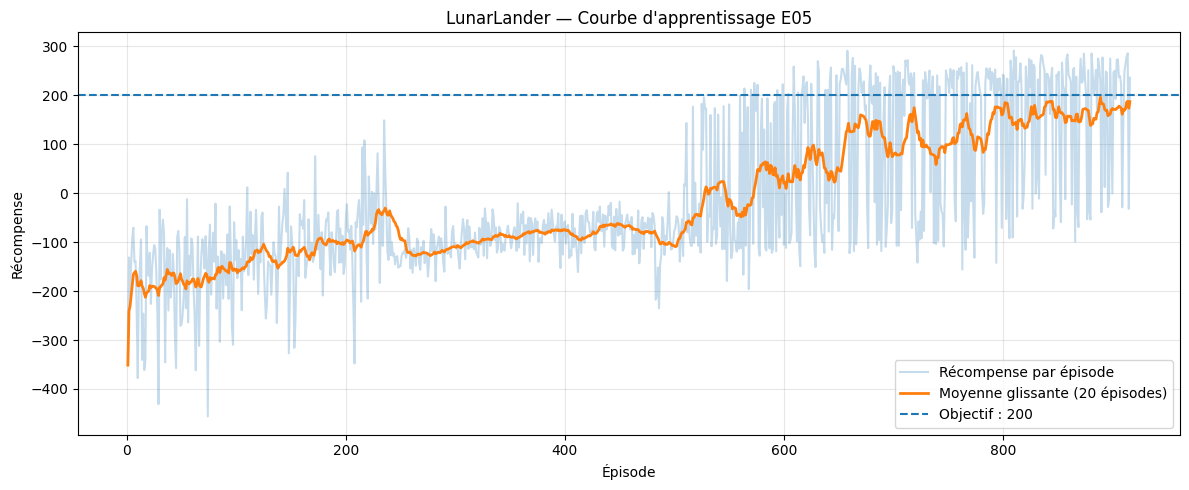

Graphique sauvegardé : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/figures/dqn_lunarlander_E05_learning_curve.png


In [38]:
import matplotlib.pyplot as plt
import pandas as pd

training_e05_df = pd.read_csv(
    METRICS_DIR / "dqn_lunarlander_E05_training.csv"
)

# Moyenne glissante sur 20 épisodes
training_e05_df["reward_smooth"] = (
    training_e05_df["reward"]
    .rolling(window=20, min_periods=1)
    .mean()
)

plt.figure(figsize=(12, 5))
plt.plot(
    training_e05_df["episode"],
    training_e05_df["reward"],
    alpha=0.25,
    label="Récompense par épisode",
)
plt.plot(
    training_e05_df["episode"],
    training_e05_df["reward_smooth"],
    linewidth=2,
    label="Moyenne glissante (20 épisodes)",
)
plt.axhline(200, linestyle="--", label="Objectif : 200")
plt.xlabel("Épisode")
plt.ylabel("Récompense")
plt.title("LunarLander — Courbe d'apprentissage E05")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / "dqn_lunarlander_E05_learning_curve.png"
plt.savefig(figure_path, dpi=150)
plt.show()

print("Graphique sauvegardé :", figure_path)

La moyenne glissante passe d’environ −350 à presque 200 : cela suggère que l’agent apprend progressivement à piloter le module lunaire.

Mais il faut distinguer deux choses :

- **Pendant l’entraînement :** la moyenne glissante approche 200, ce qui est encourageant.
- **Pendant l’évaluation indépendante :** E05 obtient 157,39 sur 100 épisodes. C’est cette mesure qui compte pour vérifier l’objectif du projet.

- **Prochaine expérience : E06 — prolonger l’entraînement**
Nous conserverons les paramètres d’E05 (learning_rate=0.0003, gamma=0.995, batch_size=32) et augmenterons uniquement le budget d’entraînement, de 500 000 à 1 000 000 de pas.
Pour éviter de repartir de zéro, nous allons charger le modèle final E05 et poursuivre son apprentissage. C’est une expérience complémentaire utile, même si un entraînement plus long ne garantit pas un meilleur score.

In [39]:
# E06 : préparer poursuite de l'entrainement
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import EvalCallback
import gymnasium as gym

EXP_ID_E06 = "E06_continue_training"
TRAIN_SEED_E06 = 42

# Reprendre le modèle final E05
model_e06 = DQN.load(
    str(MODELS_DIR / "dqn_lunarlander_E05_gamma_0995.zip"),
    device="auto",
)

# Nouvel environnement pour poursuivre l'entraînement
env_e06 = Monitor(gym.make("LunarLander-v3"))
env_e06.reset(seed=TRAIN_SEED_E06)
model_e06.set_env(env_e06)

# Environnement dédié aux évaluations intermédiaires
eval_env_e06 = Monitor(gym.make("LunarLander-v3"))

BEST_E06_DIR = MODELS_DIR / "E06_best"
BEST_E06_DIR.mkdir(parents=True, exist_ok=True)

EVAL_E06_LOG_DIR = METRICS_DIR / "E06_eval_callback"
EVAL_E06_LOG_DIR.mkdir(parents=True, exist_ok=True)

eval_callback_e06 = EvalCallback(
    eval_env_e06,
    best_model_save_path=str(BEST_E06_DIR),
    log_path=str(EVAL_E06_LOG_DIR),
    eval_freq=25_000,
    n_eval_episodes=10,
    deterministic=True,
    render=False,
    verbose=1,
)

callback_e06 = ExperimentRewardCallback()

print("Expérience :", EXP_ID_E06)
print("Modèle de départ : E05 final")
print("Pas supplémentaires prévus : 500 000")
print("Budget cumulé visé : environ 1 000 000 de pas")
print("Learning rate :", model_e06.learning_rate)
print("Gamma :", model_e06.gamma)
print("Batch size :", model_e06.batch_size)

Wrapping the env in a DummyVecEnv.
Expérience : E06_continue_training
Modèle de départ : E05 final
Pas supplémentaires prévus : 500 000
Budget cumulé visé : environ 1 000 000 de pas
Learning rate : 0.0003
Gamma : 0.995
Batch size : 32


In [40]:
# E06: poursuivre l'entraînement
model_e06.learn(
    total_timesteps=500_000,
    tb_log_name=EXP_ID_E06,
    callback=[callback_e06, eval_callback_e06],
    reset_num_timesteps=False,
)

# Sauvegarder le modèle après continuation
FINAL_E06_PATH = MODELS_DIR / "dqn_lunarlander_E06_continue_training"
model_e06.save(str(FINAL_E06_PATH))

# Sauvegarder l'historique des épisodes de cette phase
training_e06_df = pd.DataFrame({
    "episode": range(1, len(callback_e06.rewards) + 1),
    "reward": callback_e06.rewards,
    "length": callback_e06.lengths,
})

training_e06_df.to_csv(
    METRICS_DIR / "dqn_lunarlander_E06_training.csv",
    index=False,
)

print("\n=== Entraînement E06 terminé ===")
print("Épisodes terminés pendant cette phase :", len(callback_e06.rewards))

if len(callback_e06.rewards) >= 20:
    print(
        "Récompense moyenne des 20 derniers épisodes :",
        round(np.mean(callback_e06.rewards[-20:]), 2),
    )

print("Modèle sauvegardé :", str(FINAL_E06_PATH) + ".zip")
print("Historique sauvegardé :", METRICS_DIR / "dqn_lunarlander_E06_training.csv")
print("Meilleur checkpoint intermédiaire :", BEST_E06_DIR / "best_model.zip")

Logging to /mnt/projects/vk_oc_projet11_reinforcement_learning/logs/lunarlander/E06_continue_training_0
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 431      |
|    ep_rew_mean      | 174      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 920      |
|    fps              | 2442     |
|    time_elapsed     | 0        |
|    total_timesteps  | 501839   |
| train/              |          |
|    learning_rate    | 0.0003   |
|    loss             | 0.969    |
|    n_updates        | 125434   |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 428      |
|    ep_rew_mean      | 172      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 924      |
|    fps              | 2711     |
|    time_elapsed     | 1        |
|    total_timesteps  | 503321   |
| train/             

La récompense moyenne des 20 derniers épisodes atteint 200,72. C'est la première fois que nous dépassons 200 sur cette fenêtre d'entraînement.

In [41]:
# E06 : évaluation sur 100 épisodes 
from stable_baselines3 import DQN
import gymnasium as gym
import numpy as np
import pandas as pd

FINAL_E06_PATH = MODELS_DIR / "dqn_lunarlander_E06_continue_training.zip"
model_final_e06 = DQN.load(str(FINAL_E06_PATH), device="auto")

eval_env = gym.make("LunarLander-v3")
rewards_e06 = []
lengths_e06 = []

for seed in range(2026, 2126):
    obs, info = eval_env.reset(seed=seed)
    episode_reward = 0.0
    episode_length = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = model_final_e06.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env.step(int(action))
        episode_reward += reward
        episode_length += 1

    rewards_e06.append(episode_reward)
    lengths_e06.append(episode_length)

eval_env.close()

mean_e06 = float(np.mean(rewards_e06))
std_e06 = float(np.std(rewards_e06, ddof=1))

print("=== Évaluation E06 — 100 épisodes ===")
print(f"Récompense moyenne : {mean_e06:.2f}")
print(f"Écart-type : {std_e06:.2f}")
print(f"Durée moyenne : {np.mean(lengths_e06):.1f} étapes")
print("Objectif moyen >= 200 :", mean_e06 >= 200)

# Sauvegarder les résultats pour le rapport
eval_e06_df = pd.DataFrame({
    "seed": range(2026, 2126),
    "reward": rewards_e06,
    "length": lengths_e06,
})

eval_e06_df.to_csv(
    METRICS_DIR / "dqn_lunarlander_E06_eval_100.csv",
    index=False,
)

print("Résultats sauvegardés :", METRICS_DIR / "dqn_lunarlander_E06_eval_100.csv")

=== Évaluation E06 — 100 épisodes ===
Récompense moyenne : 195.77
Écart-type : 70.27
Durée moyenne : 578.4 étapes
Objectif moyen >= 200 : False
Résultats sauvegardés : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E06_eval_100.csv


#### Analyse des expériences LunarLander — E01 à E06

Notre démarche est cohérente avec un projet d'apprentissage par renforcement : nous avons établi une référence, modifié des hyperparamètres, comparé les modèles sur les mêmes 100 graines, puis prolongé l'entraînement du modèle le plus prometteur.

Il faut toutefois distinguer deux objectifs : améliorer le modèle et démontrer rigoureusement l'effet d'un hyperparamètre. Les expériences que nous avons menées servent ces deux objectifs à des degrés différents.

#### Bilan des résultats obtenus

Voici les résultats d'évaluation sur 100 épisodes, avec une politique déterministe et les graines 2026 à 2125.

| Expérience | Modification | Récompense moyenne | Écart-type |
|---|---|---:|---:|
| Baseline | Paramètres par défaut, 100k pas | -110,09 | 55,33 |
| E01 | Entraînement prolongé à 500k pas | -14,17 | 139,49 |
| E02 | Taux d'apprentissage à 0,0003 | 129,26 | 120,16 |
| E03 | Taux d'apprentissage à 0,0005 | 14,62 | 68,47 |
| E04 | Taille de batch à 64 | -14,24 | 114,94 |
| E05 | Gamma à 0,995, entraînement de 500k pas | 157,39 | 115,99 |
| E06 | Poursuite de l'entraînement d'E05 jusqu'à 1M de pas | Résultat à reporter l'évaluation | Résultat à reporter |

#### Expériences contrôlées : E02, E03, E04 et E05

Nous avons fait varier un seul hyperparamètre à la fois, en conservant les autres paramètres et le budget de 500 000 pas

Le résultat de E06 est encourageant : 195,77 de récompense moyenne sur 100 épisodes. Nous sommes maintenant à seulement 4,23 points de l'objectif de dépasser 200. Il faut néanmoins rester rigoureux : l'objectif n'est pas encore atteint.

A ce stade, nous avons une progression mesurée, des expériences documentées et un modèle nettement meilleur que la baseline. Le bilan ci-dessous permettra de décider comment continuer les expériences pour arriver à l'objectif sans repartir nécessairement de 0.

#### Analyse des résultats E01 à E06

| Expérience | Modification principale | Moyenne / 100 épisodes | Écart-type |
|---|---|---:|---:|
| Baseline | DQN par défaut, 100k pas | -110,09 | 55,33 |
| E01 | Entraînement prolongé à 500k pas | -14,17 | 139,49 |
| E02 | `learning_rate = 0.0003` | 129,26 | 120,16 |
| E03 | `learning_rate = 0.0005` | 14,62 | 68,47 |
| E04 | `batch_size = 64` | -14,24 | 114,94 |
| E05 | `gamma = 0.995`, 500k pas | 157,39 | 115,99 |
| E06 | Continuation d'E05 jusqu'à 1M de pas | 195,77 | 70,27 |

#### Ce que nous pouvons en déduire

- L'apprentissage progresse fortement. La moyenne d'évaluation est passée de -110,09 pour la baseline à 195,77 pour E06.
- E05 a amélioré le meilleur résultat connu. Son score de 157,39 dépasse les 129,26 d'E02.
- E06 confirme l'intérêt de poursuivre l'entraînement dans cette configuration. Sa moyenne augmente de 38,38 points par rapport à E05.
- La variabilité a diminué. L'écart-type passe de 115,99 pour E05 à 70,27 pour E06. C'est encourageant, même si certaines situations restent difficiles pour l'agent.

Attention : l'écart-type de 70,27 est la dispersion des récompenses entre les épisodes, pas l'incertitude sur la moyenne. Et une moyenne de 195,77 ne signifie pas que chaque épisode rapporte près de 200 points.

#### Expériences contrôlées ou expériences d'amélioration ?

Nous avons utilisé les deux approches. Elles sont complémentaires et toutes les deux pertinentes dans un projet d'apprentissage par renforcement.

#### Expériences contrôlées : E02 à E05

Nous avons modifié un hyperparamètre à la fois, avec un budget de 500 000 pas et une évaluation commune sur les mêmes 100 graines.

Cela nous permet d'étudier l'effet des modifications dans les conditions testées. E03 montre notamment que le taux d'apprentissage de 0,0005 n'a pas fait mieux que 0,0003. E05 montre que `gamma = 0.995` est prometteur par rapport à `gamma = 0.99`.

Cette comparaison reste toutefois limitée à une configuration et à une graine d'entraînement ; elle ne prouve pas que les résultats seront identiques pour d'autres initialisations.

#### Expérience d'amélioration : E06

Nous avons repris les poids d'E05 et poursuivi leur entraînement avec les mêmes hyperparamètres, jusqu'à environ un million de pas cumulés.

Cela reste acceptable car l'objectif est aussi de construire un agent performant à partir du meilleur modèle disponible. E06 n'est cependant pas un entraînement indépendant : le modèle conserve l'historique d'apprentissage d'E05. Nous pouvons donc conclure que cette continuation a donné un meilleur résultat observé, mais pas qu'un million de pas garantit toujours ce gain.

#### Pourquoi est-ce méthodologiquement acceptable ?

Un projet d'optimisation ne se limite pas à lancer des entraînements indépendants. Il est normal d'utiliser les expériences contrôlées pour comprendre le comportement des hyperparamètres, puis de mener des expériences d'amélioration pour exploiter les configurations prometteuses.

Pour être rigoureux, nous devons simplement :

- conserver les paramètres, graines, budgets et chemins des modèles ;
- identifier explicitement le modèle de départ d'une continuation ;
- distinguer les évaluations intermédiaires sur 10 épisodes des évaluations de comparaison

In [42]:
# Evaluer le meilleur checkpoint E06
from stable_baselines3 import DQN
import gymnasium as gym
import numpy as np
import pandas as pd

BEST_E06_PATH = BEST_E06_DIR / "best_model.zip"

assert BEST_E06_PATH.exists(), (
    f"Checkpoint introuvable : {BEST_E06_PATH}"
)

best_model_e06 = DQN.load(str(BEST_E06_PATH), device="auto")

eval_env = gym.make("LunarLander-v3")
rewards_best_e06 = []
lengths_best_e06 = []

for seed in range(2026, 2126):
    obs, info = eval_env.reset(seed=seed)
    episode_reward = 0.0
    episode_length = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = best_model_e06.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env.step(int(action))
        episode_reward += reward
        episode_length += 1

    rewards_best_e06.append(episode_reward)
    lengths_best_e06.append(episode_length)

eval_env.close()

mean_best_e06 = float(np.mean(rewards_best_e06))
std_best_e06 = float(np.std(rewards_best_e06, ddof=1))

print("=== Évaluation E06 — meilleur checkpoint ===")
print(f"Récompense moyenne : {mean_best_e06:.2f}")
print(f"Écart-type : {std_best_e06:.2f}")
print(f"Durée moyenne : {np.mean(lengths_best_e06):.1f} étapes")
print("Objectif moyen >= 200 :", mean_best_e06 >= 200)

pd.DataFrame({
    "seed": range(2026, 2126),
    "reward": rewards_best_e06,
    "length": lengths_best_e06,
}).to_csv(
    METRICS_DIR / "dqn_lunarlander_E06_best_checkpoint_eval_100.csv",
    index=False,
)

print("Résultats sauvegardés dans les métriques du projet.")

=== Évaluation E06 — meilleur checkpoint ===
Récompense moyenne : 179.97
Écart-type : 115.17
Durée moyenne : 564.6 étapes
Objectif moyen >= 200 : False
Résultats sauvegardés dans les métriques du projet.


Nous avons maintenant une comparaison importante : le modèle final E06 reste notre meilleur candidat, avec une moyenne de 195,77 sur 100 épisodes, contre 179,97 pour le meilleur checkpoint intermédiaire.

Nous n'avons pas encore atteint l'objectif de 200, mais nous sommes très proches. La prochaine étape est de poursuivre l'amélioration du modèle final plutôt que de revenir au checkpoint moins performant.

#### Bilan actualisé

| Modèle | Moyenne sur 100 épisodes | Écart-type |
|---|---:|---:|
| E02 | 129,26 | 120,16 |
| E05 final | 157,39 | 115,99 |
| E06, meilleur checkpoint | 179,97 | 115,17 |
| E06 final | 195,77 | 70,27 |
| Objectif | ≥ 200 | — |

**Analyse :** la continuation d'E05 jusqu'à un million de pas a amélioré la moyenne et réduit la variabilité observée. Le checkpoint intermédiaire, sélectionné à partir d'évaluations sur 10 épisodes, n'a pas fait mieux sur les 100 épisodes de comparaison. Cela confirme l'intérêt de conserver l'évaluation complète sur 100 épisodes comme mesure principale.

#### Prochaine expérience : E07

E07 sera une expérience d'amélioration, et non une expérience contrôlée indépendante : reprendre E06 final et continuer l'entraînement pendant 250 000 pas supplémentaires, sans modifier les hyperparamètres.

#### Pourquoi ce choix ?

- E06 progresse encore pendant l'entraînement.
- Nous sommes à 4,23 points de la cible.
- Continuer le modèle existant est plus économique que recommencer à zéro.
- Nous enregistrerons les résultats séparément pour ne pas confondre E07 avec E06.

Cette stratégie ne garantit pas que la moyenne dépassera 200. Si elle stagne ou diminue, nous réexaminerons la configuration.

In [43]:
# Préparer E07
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import EvalCallback
import gymnasium as gym

EXP_ID_E07 = "E07_continue_250k"
TRAIN_SEED_E07 = 42

# Reprendre le modèle final E06
model_e07 = DQN.load(
    str(MODELS_DIR / "dqn_lunarlander_E06_continue_training.zip"),
    device="auto",
)

# Nouvel environnement d'entraînement
env_e07 = Monitor(gym.make("LunarLander-v3"))
env_e07.reset(seed=TRAIN_SEED_E07)
model_e07.set_env(env_e07)

# Environnement distinct pour les évaluations intermédiaires
eval_env_e07 = Monitor(gym.make("LunarLander-v3"))

BEST_E07_DIR = MODELS_DIR / "E07_best"
BEST_E07_DIR.mkdir(parents=True, exist_ok=True)

EVAL_E07_LOG_DIR = METRICS_DIR / "E07_eval_callback"
EVAL_E07_LOG_DIR.mkdir(parents=True, exist_ok=True)

eval_callback_e07 = EvalCallback(
    eval_env_e07,
    best_model_save_path=str(BEST_E07_DIR),
    log_path=str(EVAL_E07_LOG_DIR),
    eval_freq=25_000,
    n_eval_episodes=10,
    deterministic=True,
    render=False,
    verbose=1,
)

callback_e07 = ExperimentRewardCallback()

print("Expérience :", EXP_ID_E07)
print("Modèle de départ : E06 final")
print("Pas supplémentaires prévus : 250 000")
print("Budget cumulé visé : environ 1 250 000 pas")
print("Learning rate :", model_e07.learning_rate)
print("Gamma :", model_e07.gamma)
print("Batch size :", model_e07.batch_size)

Wrapping the env in a DummyVecEnv.
Expérience : E07_continue_250k
Modèle de départ : E06 final
Pas supplémentaires prévus : 250 000
Budget cumulé visé : environ 1 250 000 pas
Learning rate : 0.0003
Gamma : 0.995
Batch size : 32


In [44]:
# E07 : lancer l'entraînement
model_e07.learn(
    total_timesteps=250_000,
    tb_log_name=EXP_ID_E07,
    callback=[callback_e07, eval_callback_e07],
    reset_num_timesteps=False,
)

# Sauvegarder le modèle final E07
FINAL_E07_PATH = MODELS_DIR / "dqn_lunarlander_E07_continue_250k"
model_e07.save(str(FINAL_E07_PATH))

# Sauvegarder l'historique de cette phase d'entraînement
training_e07_df = pd.DataFrame({
    "episode": range(1, len(callback_e07.rewards) + 1),
    "reward": callback_e07.rewards,
    "length": callback_e07.lengths,
})

training_e07_df.to_csv(
    METRICS_DIR / "dqn_lunarlander_E07_training.csv",
    index=False,
)

print("\n=== Entraînement E07 terminé ===")
print("Épisodes terminés pendant cette phase :", len(callback_e07.rewards))

if len(callback_e07.rewards) >= 20:
    print(
        "Récompense moyenne des 20 derniers épisodes :",
        round(np.mean(callback_e07.rewards[-20:]), 2),
    )

print("Modèle sauvegardé :", str(FINAL_E07_PATH) + ".zip")
print("Historique sauvegardé :", METRICS_DIR / "dqn_lunarlander_E07_training.csv")
print("Meilleur checkpoint intermédiaire :", BEST_E07_DIR / "best_model.zip")

Logging to /mnt/projects/vk_oc_projet11_reinforcement_learning/logs/lunarlander/E07_continue_250k_0
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 623      |
|    ep_rew_mean      | 182      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 1696     |
|    fps              | 2261     |
|    time_elapsed     | 0        |
|    total_timesteps  | 1001000  |
| train/              |          |
|    learning_rate    | 0.0003   |
|    loss             | 0.0442   |
|    n_updates        | 250224   |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 635      |
|    ep_rew_mean      | 178      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 1700     |
|    fps              | 2893     |
|    time_elapsed     | 1        |
|    total_timesteps  | 1005000  |
| train/              |  

In [45]:
# E07 : évaluation sur 100 épisodes 

# Charger le modèle final E07
model_final_e07 = DQN.load(
    str(MODELS_DIR / "dqn_lunarlander_E07_continue_250k.zip"),
    device="auto",
)

eval_env = gym.make("LunarLander-v3")

rewards_e07 = []
lengths_e07 = []

# Même série de 100 graines que pour les évaluations précédentes
for seed in range(2026, 2126):
    obs, info = eval_env.reset(seed=seed)

    episode_reward = 0.0
    episode_length = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = model_final_e07.predict(
            obs,
            deterministic=True,
        )

        obs, reward, terminated, truncated, info = eval_env.step(
            int(action)
        )

        episode_reward += reward
        episode_length += 1

    rewards_e07.append(episode_reward)
    lengths_e07.append(episode_length)

eval_env.close()

mean_e07 = float(np.mean(rewards_e07))
std_e07 = float(np.std(rewards_e07, ddof=1))
mean_length_e07 = float(np.mean(lengths_e07))

print("=== Évaluation finale E07 — 100 épisodes ===")
print(f"Récompense moyenne : {mean_e07:.2f}")
print(f"Écart-type          : {std_e07:.2f}")
print(f"Durée moyenne       : {mean_length_e07:.1f} étapes")
print(f"Objectif >= 200     : {'ATTEINT' if mean_e07 >= 200 else 'NON ATTEINT'}")

# Enregistrer les résultats pour le rapport du projet
eval_e07_df = pd.DataFrame({
    "seed": range(2026, 2126),
    "reward": rewards_e07,
    "length": lengths_e07,
})

eval_e07_df.to_csv(
    METRICS_DIR / "dqn_lunarlander_E07_eval_100.csv",
    index=False,
)

print(
    "Résultats enregistrés :",
    METRICS_DIR / "dqn_lunarlander_E07_eval_100.csv",
)


=== Évaluation finale E07 — 100 épisodes ===
Récompense moyenne : 222.86
Écart-type          : 56.50
Durée moyenne       : 483.7 étapes
Objectif >= 200     : ATTEINT
Résultats enregistrés : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E07_eval_100.csv


Le résultat de l'expérience E07 indique un dépassement du seuil de 200 points sur une évaluation de 100 épisodes, et la variabilité est nettement plus faible que lors des essais précédents.

Il faut maintenant présenter les expériences de manière rigoureuse, en distinguant les expériences contrôlées des expériences d’amélioration par poursuite de l’entraînement. 

#### Analyse du meilleur résultat : E07

**E07 — évaluation finale sur 100 épisodes**

# 222,86

Récompense moyenne

# 56,50

Écart-type

## +22,86

Points au-dessus du seuil

## 483,7

Étapes moyennes par épisode

**Objectif de 200 points atteint sur 100 épisodes.**

#### Ce que les chiffres permettent de dire

- **Performance :** la moyenne de 222,86 dépasse le seuil de 200 de 22,86 points. Le résultat satisfait donc le critère chiffré demandé pour l’évaluation.
- **Régularité :** l’écart-type passe à 56,50, ce qui représente une dispersion sensiblement plus faible que pour E06 (70,27), E05 (115,99) ou E02 (120,16).
- **Progression :** par rapport à E06, la moyenne augmente de 195,77 à 222,86, soit +27,09 points, tandis que l’écart-type diminue de 70,27 à 56,50.
- **Durée des épisodes :** 483,7 étapes en moyenne, contre 578,4 pour E06. Cela suggère que l’agent termine généralement ses épisodes en moins d’étapes, mais cette durée seule ne prouve pas que tous les atterrissages sont réussis.

La prudence importante concerne la notion de stabilité : une moyenne supérieure à 200 sur 100 épisodes, avec un écart-type de 56,50, est un résultat encourageant. En revanche, cela ne signifie pas que chaque épisode dépasse 200 points, ni que la performance sera identique sur toutes les graines aléatoires possibles. Le seuil est atteint sur le protocole d’évaluation utilisé. **Une validation sur de nouvelles graines renforcerait encore la conclusion.**

#### Expériences contrôlées et expériences d’amélioration : quelle différence ?

##### Les expériences contrôlées : E01 à E05

Une expérience contrôlée sert à étudier l’effet d’un changement précis. Pour cela, on conserve autant que possible les autres paramètres : architecture du réseau, budget d’entraînement, méthode d’évaluation et graines aléatoires.

Dans les essais réalisés plus haut, les expériences E01 à E05 ont été entraînées sur 500 000 pas chacune et évaluées sur les mêmes 100 graines. Ci-dessous la comparaison :

| Expérience | Modification principale | Moyenne / 100 épisodes | Écart-type |
|---|---|---:|---:|
| Référence initiale | DQN par défaut, 100 000 pas | -110,09 | 55,33 |
| E01 | Entraînement prolongé à 500 000 pas, LR = 0,0001 | -14,17 | 139,49 |
| E02 | LR = 0,0003 | 129,26 | 120,16 |
| E03 | LR = 0,0005 | 14,62 | 68,47 |
| E04 | Batch size = 64 | -14,24 | 114,94 |
| E05 | Gamma = 0,995 | 157,39 | 115,99 |

LR = learning rate, ou taux d’apprentissage. Les résultats sont ceux des évaluations précédentes.

**Comment justifier ces essais ?**

- **E01 :** permet de constater que prolonger l’entraînement à 500 000 pas améliore la moyenne par rapport au modèle de référence. Toutefois, le budget d’entraînement change également : il ne s’agit donc pas d’une comparaison isolant un hyperparamètre à budget constant.
- **E02 :** en passant à un learning rate de 0,0003, la moyenne progresse fortement par rapport à E01. Comme E01 et E02 ont le même budget et les mêmes autres paramètres annoncés, cette comparaison apporte un indice favorable à ce taux d’apprentissage.
- **E03 :** le learning rate de 0,0005 produit un résultat nettement inférieur à E02. Cela montre que l’augmentation du taux d’apprentissage n’améliore pas systématiquement l’apprentissage.
- **E04 :** le passage à un batch size de 64 donne une moyenne inférieure à celle d’E02. Dans les conditions testées, cette configuration n’a pas apporté l’amélioration recherchée.
- **E05 :** le passage de gamma = 0,99 à gamma = 0,995 améliore la moyenne de 129,26 à 157,39, avec les autres paramètres principaux conservés. Cela suggère qu’un facteur d’actualisation plus élevé est intéressant pour ce problème.

La limite à expliciter : E02 constitue la comparaison la plus directement favorable au learning rate de 0,0003 face à E01. E03 et E04 apportent des comparaisons complémentaires, mais E03 modifie à nouveau le learning rate et E04 le batch size. Il faut donc présenter les résultats comme des observations expérimentales, pas comme une preuve universelle de l’effet de chaque hyperparamètre.

#### Les expériences d’amélioration : E06 et E07

Ces deux essais répondent à une autre question : une fois une configuration prometteuse identifiée, peut-on améliorer encore le même agent en poursuivant son entraînement ?

##### E06 — poursuite de l’entraînement de E05

**500 000 pas supplémentaires, mêmes hyperparamètres principaux.**

Le modèle E05 est chargé puis entraîné pendant 500 000 pas supplémentaires. La moyenne passe de 157,39 à 195,77 sur 100 épisodes. C’est une amélioration notable, mais la moyenne reste sous le seuil demandé.

##### E07 — poursuite de l’entraînement de E06

**250 000 pas supplémentaires, mêmes hyperparamètres principaux.**

Le modèle E06 est chargé puis entraîné pendant 250 000 pas supplémentaires. La moyenne atteint 222,86 sur 100 épisodes, avec un écart-type de 56,50. C’est le meilleur résultat final obtenu jusqu’ici.

Ces expériences sont tout à fait légitimes. Elles ne sont simplement pas des expériences contrôlées d’un nouvel hyperparamètre : elles étudient l’effet pratique de la poursuite de l’entraînement à partir de poids déjà appris.

E06 et E07 conservent notamment le learning rate de 0,0003, gamma de 0,995 et batch size de 32. Ce qui change est le nombre de pas d’entraînement supplémentaires et l’état du modèle au départ.

Il faut donc écrire que la poursuite de l’entraînement est associée à une amélioration de la performance observée, et non qu’elle garantit à elle seule cette amélioration dans tous les contextes.

Ci-dessous la synthèse de ce qui a été réalisé à ce stade:

| Attente OpenClassrooms | Ce qui a été réalisé |
|---|---|
| Établir un modèle de référence | DQN de référence évalué sur 100 épisodes |
| Expérimenter sur les hyperparamètres | E02 à E05 comparent différentes valeurs du learning rate, du batch size et de gamma |
| Isoler l’effet d’un paramètre | Comparaisons à budget et conditions similaires, notamment E01/E02, E02/E03, E02/E04 et E02/E05 |
| Améliorer les performances | Poursuite de l’entraînement avec E06, puis E07 |
| Évaluer sur 100 épisodes | Évaluations comparables sur une série commune de graines |
| Documenter les résultats | Historique CSV des expériences et évaluations |
| Sauvegarder les modèles prometteurs | Modèles E05, E06 et E07 sauvegardés |
| Utiliser TensorBoard ou équivalent | Journaux d’entraînement configurés pour le suivi ; CSV disponibles pour les comparaisons |


In [46]:
# E07 : test de robustesse sur 100 nouvelles graines

# Validation complémentaire d'E07 sur 100 nouvelles graines
# Aucun réentraînement : on évalue le modèle sauvegardé.

from stable_baselines3 import DQN
import gymnasium as gym
import numpy as np
import pandas as pd

ROBUSTNESS_CSV = METRICS_DIR / "dqn_lunarlander_E07_robustness_100.csv"

model_e07_robust = DQN.load(
    str(MODELS_DIR / "dqn_lunarlander_E07_continue_250k.zip"),
    device="auto",
)

robust_env = gym.make("LunarLander-v3")

robust_seeds = range(3000, 3100)
robust_rewards = []
robust_lengths = []

for seed in robust_seeds:
    obs, info = robust_env.reset(seed=seed)

    total_reward = 0.0
    episode_length = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = model_e07_robust.predict(
            obs,
            deterministic=True,
        )

        obs, reward, terminated, truncated, info = robust_env.step(
            int(action)
        )

        total_reward += float(reward)
        episode_length += 1

    robust_rewards.append(total_reward)
    robust_lengths.append(episode_length)

robust_env.close()

robust_mean = float(np.mean(robust_rewards))
robust_std = float(np.std(robust_rewards, ddof=1))
robust_median = float(np.median(robust_rewards))
robust_min = float(np.min(robust_rewards))
robust_max = float(np.max(robust_rewards))
robust_success_rate = float(np.mean(np.array(robust_rewards) >= 200) * 100)

robust_df = pd.DataFrame({
    "seed": list(robust_seeds),
    "reward": robust_rewards,
    "length": robust_lengths,
})

robust_df.to_csv(ROBUSTNESS_CSV, index=False)

print("=== Robustesse E07 — 100 nouvelles graines ===")
print(f"Récompense moyenne : {robust_mean:.2f}")
print(f"Écart-type          : {robust_std:.2f}")
print(f"Médiane             : {robust_median:.2f}")
print(f"Minimum             : {robust_min:.2f}")
print(f"Maximum             : {robust_max:.2f}")
print(f"Épisodes à >= 200    : {robust_success_rate:.1f} %")
print(f"Durée moyenne       : {np.mean(robust_lengths):.1f} étapes")
print(f"Moyenne >= 200      : {robust_mean >= 200}")
print("Résultats sauvegardés :", ROBUSTNESS_CSV)


=== Robustesse E07 — 100 nouvelles graines ===
Récompense moyenne : 220.06
Écart-type          : 66.21
Médiane             : 221.31
Minimum             : 8.80
Maximum             : 315.45
Épisodes à >= 200    : 71.0 %
Durée moyenne       : 497.1 étapes
Moyenne >= 200      : True
Résultats sauvegardés : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/dqn_lunarlander_E07_robustness_100.csv


#### Que nous apprennent les deux évaluations ?

#### Comparaison du modèle E07

**Première série · 100 épisodes**

# 222,86

Écart-type : 56,50

**Nouvelles graines · 100 épisodes**

# 220,06

Écart-type : 66,21

## 71 %

des épisodes à 200 points ou plus

## 220,06

moyenne sur les nouvelles graines

#### Interprétation

- **La moyenne est reproductible :** elle passe de 222,86 à 220,06, soit seulement 2,80 points d’écart entre les deux séries.
- **L’objectif moyen est atteint deux fois :** les deux séries de 100 épisodes dépassent 200 points.
- **La dispersion reste notable :** l’écart-type passe de 56,50 à 66,21 sur la seconde série. 
- **L’agent n’est pas infaillible :** 71 % des épisodes atteignent au moins 200 points. Une moyenne supérieure à 200 ne signifie donc pas que chaque atterrissage est réussi ou que chaque épisode dépasse ce seuil.

Il faut aussi noter que la récompense minimale de 8,80 montre qu’il existe des épisodes nettement moins performants. La consigne demande une moyenne stable avec un écart-type faible, mais ne fixe pas de valeur maximale précise pour cet écart-type. On ne peut donc pas affirmer automatiquement que 66,21 est « faible » : il faut l’interpréter par rapport à tes essais précédents et à la distribution des récompenses.

**A ce stade :** E07 est actuellement un bon modèle candidat, avec une moyenne robuste autour de 220, mais la régularité des épisodes peut encore être améliorée. 

#### La prochaine étape : analyser les épisodes faibles avant de réentraîner
**Une analyse diagnostique de la distribution des récompenses d’E07 permettra de savoir si la moyenne est tirée vers le bas par quelques échecs isolés ou si les épisodes sont globalement trop variables.**

,Série,Épisodes,Moyenne,Écart-type,Q1 (25 %),Médiane,Q3 (75 %),Épisodes < 200 (%)
0,E07 — évaluation initiale,100,222.86,56.50,189.25,222.45,269.19,29.0
1,E07 — nouvelles graines,100,220.06,66.21,190.17,221.31,274.80,29.0
2,E07 — ensemble des 200 épisodes,200,221.46,61.41,189.45,222.10,272.03,29.0


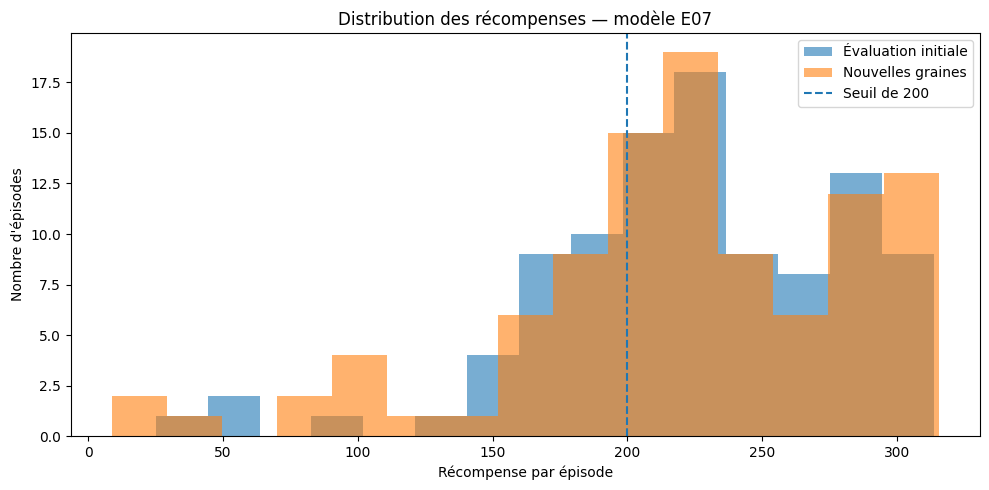

Diagnostic sauvegardé.


In [47]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Charger les deux évaluations d'E07
eval_initial = pd.read_csv(
    METRICS_DIR / "dqn_lunarlander_E07_eval_100.csv"
)
eval_robust = pd.read_csv(
    METRICS_DIR / "dqn_lunarlander_E07_robustness_100.csv"
)

r_initial = eval_initial["reward"].dropna().to_numpy()
r_robust = eval_robust["reward"].dropna().to_numpy()
r_combined = np.concatenate([r_initial, r_robust])

# Tableau statistique
diagnostic = pd.DataFrame([
    {
        "Série": "E07 — évaluation initiale",
        "Épisodes": len(r_initial),
        "Moyenne": np.mean(r_initial),
        "Écart-type": np.std(r_initial, ddof=1),
        "Q1 (25 %)": np.percentile(r_initial, 25),
        "Médiane": np.median(r_initial),
        "Q3 (75 %)": np.percentile(r_initial, 75),
        "Épisodes < 200 (%)": np.mean(r_initial < 200) * 100,
    },
    {
        "Série": "E07 — nouvelles graines",
        "Épisodes": len(r_robust),
        "Moyenne": np.mean(r_robust),
        "Écart-type": np.std(r_robust, ddof=1),
        "Q1 (25 %)": np.percentile(r_robust, 25),
        "Médiane": np.median(r_robust),
        "Q3 (75 %)": np.percentile(r_robust, 75),
        "Épisodes < 200 (%)": np.mean(r_robust < 200) * 100,
    },
    {
        "Série": "E07 — ensemble des 200 épisodes",
        "Épisodes": len(r_combined),
        "Moyenne": np.mean(r_combined),
        "Écart-type": np.std(r_combined, ddof=1),
        "Q1 (25 %)": np.percentile(r_combined, 25),
        "Médiane": np.median(r_combined),
        "Q3 (75 %)": np.percentile(r_combined, 75),
        "Épisodes < 200 (%)": np.mean(r_combined < 200) * 100,
    },
])

display(diagnostic.round(2))

# Distribution des récompenses
plt.figure(figsize=(10, 5))
plt.hist(r_initial, bins=15, alpha=0.6, label="Évaluation initiale")
plt.hist(r_robust, bins=15, alpha=0.6, label="Nouvelles graines")
plt.axvline(200, linestyle="--", label="Seuil de 200")
plt.xlabel("Récompense par épisode")
plt.ylabel("Nombre d'épisodes")
plt.title("Distribution des récompenses — modèle E07")
plt.legend()
plt.tight_layout()
plt.show()

# Enregistrer le diagnostic
diagnostic.to_csv(
    METRICS_DIR / "dqn_lunarlander_E07_distribution_diagnostic.csv",
    index=False,
)

print("Diagnostic sauvegardé.")


Ces résultats confirment que E07 est un candidat solide pour le projet, mais ils montrent aussi une variabilité.

| Série | Moyenne | Écart-type | Q1 (25 %) | Médiane | Q3 (75 %) | Épisodes sous 200 |
|---|---:|---:|---:|---:|---:|---:|
| E07 — évaluation initiale | 222,86 | 56,50 | 189,25 | 222,45 | 269,19 | 29 % |
| E07 — nouvelles graines | 220,06 | 66,21 | 190,17 | 221,31 | 274,80 | 29 % |
| E07 — ensemble des 200 épisodes | 221,46 | 61,41 | 189,45 | 222,10 | 272,03 | 29 % |

#### Analyse de la stabilité

- **Moyenne :** sur les 200 épisodes, la récompense moyenne est de 221,46 points, soit 21,46 points au-dessus du seuil demandé.
- **Reproductibilité :** les deux séries ont des moyennes proches, 222,86 et 220,06. L’écart de 2,80 points est faible au regard des récompenses observées.
- **Dispersion :** l’écart-type combiné est de 61,41. Les résultats individuels restent donc variables ; on ne peut pas qualifier cette dispersion de faible sans critère de comparaison précis.
- **Quartiles :** environ un quart des épisodes obtiennent une récompense inférieure ou égale à 189,45, tandis qu’environ trois quarts restent sous 272,03.
- **Épisodes sous 200 :** 29 % des épisodes restent sous ce seuil. Cela confirme que le modèle ne réussit pas tous ses épisodes au niveau de récompense visé, même si sa moyenne dépasse 200.

La conclusion importante est que la moyenne supérieure à 200 est robuste sur deux séries de 100 épisodes, mais la régularité individuelle reste perfectible.

Voici les résultats de référence d’E07 :

| Indicateur | E07 |
|---|---:|
| Entraînement cumulé | Environ 1 250 000 pas |
| Learning rate | 0,0003 |
| Gamma | 0,995 |
| Batch size | 32 |
| Moyenne sur 200 épisodes | 221,46 |
| Écart-type sur 200 épisodes | 61,41 |
| Épisodes sous 200 points | 29 % |

Nous allons chercher à améliorer ce résultat sans perdre le bénéfice de l’apprentissage déjà réalisé.

#### Première expérience proposée : réduire le learning rate

Tester un learning rate de 0,0001 au lieu de 0,0003, en poursuivant l’entraînement à partir des poids d’E07.

Pourquoi commencer par ce paramètre ?

- Le learning rate détermine l’amplitude des mises à jour du réseau.
- Des mises à jour plus petites peuvent aider à affiner une politique déjà performante.
- C’est une hypothèse plausible pour améliorer la stabilité, mais ce n’est pas garanti : un learning rate plus faible peut aussi ne rien améliorer, voire dégrader le modèle.

Nous garderons gamma à 0,995 et batch size à 32. Nous conserverons également E07 intact afin de pouvoir revenir à cette version si le nouvel essai est moins bon.

In [48]:
# E08 : essayer de réduire l'écart type

from stable_baselines3 import DQN
from stable_baselines3.common.callbacks import EvalCallback
import gymnasium as gym
import numpy as np
import pandas as pd

# E08 : poursuite de l'entraînement d'E07 avec un learning rate réduit
EXP_ID_E08 = "E08_learning_rate_0001"

E08_PATH = MODELS_DIR / "dqn_lunarlander_E08_learning_rate_0001"
E08_BEST_DIR = MODELS_DIR / "E08_best"
E08_BEST_DIR.mkdir(parents=True, exist_ok=True)

# Charger E07 : le fichier E07 original ne sera pas modifié
model_e08 = DQN.load(
    str(MODELS_DIR / "dqn_lunarlander_E07_continue_250k.zip"),
    device="auto",
)

# Modifier uniquement le learning rate
model_e08.learning_rate = 0.0001
model_e08.lr_schedule = lambda progress_remaining: 0.0001

# Environnements d'entraînement et d'évaluation
train_env_e08 = gym.make("LunarLander-v3")
eval_env_e08 = gym.make("LunarLander-v3")

model_e08.set_env(train_env_e08)

# Journalisation TensorBoard
model_e08.tensorboard_log = str(LOGS_DIR)

callback_e08 = ExperimentRewardCallback()

eval_callback_e08 = EvalCallback(
    eval_env_e08,
    best_model_save_path=str(E08_BEST_DIR),
    log_path=str(METRICS_DIR / "E08_eval_logs"),
    eval_freq=10_000,
    n_eval_episodes=10,
    deterministic=True,
    render=False,
)

print("Expérience :", EXP_ID_E08)
print("Modèle de départ : E07")
print("Learning rate :", model_e08.learning_rate)
print("Gamma :", model_e08.gamma)
print("Batch size :", model_e08.batch_size)
print("Pas supplémentaires prévus : 250 000")
print("Modèle E07 conservé :", (MODELS_DIR / "dqn_lunarlander_E07_continue_250k.zip").exists())


Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Expérience : E08_learning_rate_0001
Modèle de départ : E07
Learning rate : 0.0001
Gamma : 0.995
Batch size : 32
Pas supplémentaires prévus : 250 000
Modèle E07 conservé : True


In [50]:

# Entraînement complémentaire E08 avec learning rate réduit
model_e08.learn(
    total_timesteps=250_000,
    callback=[callback_e08, eval_callback_e08],
    reset_num_timesteps=False,
    tb_log_name="E08_learning_rate_0001",
    progress_bar=False,
)

# Sauvegarder le modèle dans un nouveau fichier
model_e08.save(str(E08_PATH))

# Fermer les environnements
train_env_e08.close()
eval_env_e08.close()

print("Entraînement E08 terminé.")
print("Modèle sauvegardé :", str(E08_PATH) + ".zip")
print("Épisodes terminés pendant E08 :", len(callback_e08.rewards))

if callback_e08.rewards:
    print(
        "Moyenne des 20 derniers épisodes d'entraînement :",
        round(float(np.mean(callback_e08.rewards[-20:])), 2)
    )


Logging to /mnt/projects/vk_oc_projet11_reinforcement_learning/logs/lunarlander/E08_learning_rate_0001_0
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 465      |
|    ep_rew_mean      | 220      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 2064     |
|    fps              | 2181     |
|    time_elapsed     | 0        |
|    total_timesteps  | 1250601  |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.0388   |
|    n_updates        | 312625   |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 476      |
|    ep_rew_mean      | 217      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 2068     |
|    fps              | 2712     |
|    time_elapsed     | 1        |
|    total_timesteps  | 1253213  |
| train/            

/mnt/projects/envs/dl-pytorch/lib/python3.11/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


Eval num_timesteps=1260000, episode_reward=207.43 +/- 79.49
Episode length: 406.20 +/- 231.20
----------------------------------
| eval/               |          |
|    mean_ep_length   | 406      |
|    mean_reward      | 207      |
| rollout/            |          |
|    exploration_rate | 0.05     |
| time/               |          |
|    total_timesteps  | 1260000  |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.0952   |
|    n_updates        | 314974   |
----------------------------------
New best mean reward!
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 473      |
|    ep_rew_mean      | 215      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 2084     |
|    fps              | 2656     |
|    time_elapsed     | 3        |
|    total_timesteps  | 1260345  |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss

In [51]:
# Evaluation de E08 sur 100 épisodes

from stable_baselines3.common.evaluation import evaluate_policy
import pandas as pd
import numpy as np

# Charger le modèle E08 sauvegardé
model_e08_eval = DQN.load(
    str(MODELS_DIR / "dqn_lunarlander_E08_learning_rate_0001.zip"),
    device="auto",
)

# Évaluation reproductible sur les mêmes graines qu'E07
eval_env_e08 = gym.make("LunarLander-v3")
eval_env_e08.reset(seed=2026)

rewards_e08 = []
lengths_e08 = []

for seed in range(2026, 2126):
    obs, info = eval_env_e08.reset(seed=seed)
    terminated = False
    truncated = False
    episode_reward = 0.0
    episode_length = 0

    while not (terminated or truncated):
        action, _ = model_e08_eval.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env_e08.step(action)
        episode_reward += float(reward)
        episode_length += 1

    rewards_e08.append(episode_reward)
    lengths_e08.append(episode_length)

eval_env_e08.close()

# Résumé statistique
print("E08 — Évaluation sur 100 épisodes")
print(f"Moyenne : {np.mean(rewards_e08):.2f}")
print(f"Écart-type : {np.std(rewards_e08, ddof=1):.2f}")
print(f"Médiane : {np.median(rewards_e08):.2f}")
print(f"Minimum : {np.min(rewards_e08):.2f}")
print(f"Maximum : {np.max(rewards_e08):.2f}")
print(f"Épisodes avec récompense >= 200 : {np.mean(np.array(rewards_e08) >= 200) * 100:.1f} %")

# Enregistrer les résultats
df_e08_eval = pd.DataFrame({
    "seed": range(2026, 2126),
    "reward": rewards_e08,
    "episode_length": lengths_e08,
})

df_e08_eval.to_csv(
    METRICS_DIR / "dqn_lunarlander_E08_eval_100.csv",
    index=False,
)

print("Résultats enregistrés dans outputs/metrics/dqn_lunarlander_E08_eval_100.csv")


E08 — Évaluation sur 100 épisodes
Moyenne : 244.67
Écart-type : 54.39
Médiane : 253.89
Minimum : 46.45
Maximum : 315.74
Épisodes avec récompense >= 200 : 93.0 %
Résultats enregistrés dans outputs/metrics/dqn_lunarlander_E08_eval_100.csv


Sur les mêmes 100 graines d’évaluation :

| Indicateur | E07 | E08 | Évolution |
|---|---:|---:|---:|
| Récompense moyenne | 222,86 | 244,67 | +21,81 |
| Écart-type | 56,50 | 54,39 | −2,11 |
| Médiane | — | 253,89 | — |
| Épisodes ≥ 200 points | 71 %* | 93 % | +22 points |
| Récompense minimale | — | 46,45 | — |

\*Les 71 % d’E07 proviennent de son évaluation sur 100 graines différentes ; cette proportion n’est donc pas directement comparable à celle d’E08 sur les mêmes graines que l’évaluation initiale d’E07. Les moyennes et écarts-types du tableau, eux, sont comparés sur les mêmes graines.

Le constat le plus important : la moyenne augmente de près de 22 points et l’écart-type diminue légèrement. La dispersion n’a pas chuté de façon spectaculaire, mais la proportion d’épisodes à 200 points ou plus est très encourageante.

#### Étape suivante : vérifier que l’amélioration est réelle

**Avant de choisir E08 comme meilleur modèle définitif, nous devons vérifier qu’il reste performant sur 100 nouvelles graines, jamais utilisées dans cette comparaison. Nous évaluerons E07 et E08 sur exactement les mêmes nouvelles graines, de 3100 à 3199.**

In [52]:

# Comparaison finale E07 / E08 sur 100 nouvelles graines
model_e07_test = DQN.load(
    str(MODELS_DIR / "dqn_lunarlander_E07_continue_250k.zip"),
    device="auto",
)
model_e08_test = DQN.load(
    str(MODELS_DIR / "dqn_lunarlander_E08_learning_rate_0001.zip"),
    device="auto",
)

env = gym.make("LunarLander-v3")
fresh_seeds = range(3100, 3200)
results = []

for seed in fresh_seeds:
    for model_name, model in [
        ("E07", model_e07_test),
        ("E08", model_e08_test),
    ]:
        obs, info = env.reset(seed=seed)
        terminated = False
        truncated = False
        total_reward = 0.0
        length = 0

        while not (terminated or truncated):
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, info = env.step(action)
            total_reward += float(reward)
            length += 1

        results.append({
            "model": model_name,
            "seed": seed,
            "reward": total_reward,
            "episode_length": length,
        })

env.close()

df_fresh = pd.DataFrame(results)
df_fresh.to_csv(
    METRICS_DIR / "dqn_lunarlander_E07_E08_fresh_100.csv",
    index=False,
)

for name in ["E07", "E08"]:
    subset = df_fresh[df_fresh["model"] == name]
    print(f"\n{name} — 100 nouvelles graines")
    print(f"Moyenne : {subset['reward'].mean():.2f}")
    print(f"Écart-type : {subset['reward'].std(ddof=1):.2f}")
    print(f"Médiane : {subset['reward'].median():.2f}")
    print(f"Minimum : {subset['reward'].min():.2f}")
    print(f"Épisodes >= 200 : {(subset['reward'] >= 200).mean() * 100:.1f} %")

print("\nRésultats sauvegardés dans outputs/metrics/dqn_lunarlander_E07_E08_fresh_100.csv")



E07 — 100 nouvelles graines
Moyenne : 214.36
Écart-type : 78.54
Médiane : 230.74
Minimum : 1.39
Épisodes >= 200 : 70.0 %

E08 — 100 nouvelles graines
Moyenne : 235.35
Écart-type : 61.85
Médiane : 251.91
Minimum : 40.39
Épisodes >= 200 : 85.0 %

Résultats sauvegardés dans outputs/metrics/dqn_lunarlander_E07_E08_fresh_100.csv


| Indicateur | E07 | E08 | Amélioration |
|---|---:|---:|---:|
| Moyenne | 214,36 | 235,35 | +20,99 points |
| Écart-type | 78,54 | 61,85 | −21,3 % |
| Médiane | 230,74 | 251,91 | +21,17 points |
| Minimum | 1,39 | 40,39 | +39,00 points |
| Épisodes ≥ 200 | 70 % | 85 % | +15 points |

#### Que peut-on conclure ?

Les deux évaluations d’E08 sont encourageantes :

| Évaluation | Moyenne | Écart-type |
|---|---:|---:|
| 100 graines utilisées pour comparer les premiers modèles | 244,67 | 54,39 |
| 100 nouvelles graines | 235,35 | 61,85 |

- La moyenne reste largement supérieure à 200 sur les deux séries.
- L’écart-type diminue par rapport à E07 sur les deux séries comparatives.
- Sur les nouvelles graines, la proportion d’épisodes atteignant 200 points passe de 70 % à 85 %.

**Notre hypothèse est donc soutenue par les résultats : réduire le learning rate de 0,0003 à 0,0001 pendant la poursuite de l’entraînement a été associé à une amélioration de la performance moyenne et de sa régularité. Cela ne prouve pas que le learning rate est l’unique cause, mais nous avons une comparaison expérimentale solide.**

In [53]:
# Figer E08 comme meilleur modèle

# Enregistrer le résumé de l'expérience E08
experiment_e08 = {
    "experiment_id": "E08",
    "description": "Continuation de E07 avec learning rate réduit",
    "seed": 2026,
    "total_timesteps": 250_000,
    "learning_rate": 0.0001,
    "gamma": 0.995,
    "batch_size": 32,
    "mean_reward_100": 244.67,
    "std_reward_100": 54.39,
    "model_path": "models/dqn_lunarlander_E08_learning_rate_0001.zip",
    "notes": (
        "100 graines de comparaison : moyenne 244.67, écart-type 54.39. "
        "Validation sur 100 nouvelles graines : moyenne 235.35, "
        "écart-type 61.85, 85 % des épisodes >= 200. "
        "Continuation d'E07 avec learning rate réduit."
    ),
}

experiments = pd.read_csv(EXPERIMENTS_CSV)

# Éviter de créer plusieurs lignes si la cellule est relancée
experiments = experiments[
    experiments["experiment_id"] != "E08"
]

experiments = pd.concat(
    [experiments, pd.DataFrame([experiment_e08])],
    ignore_index=True,
)

experiments.to_csv(EXPERIMENTS_CSV, index=False)

print("E08 enregistré dans le tableau des expériences.")
print("Fichier :", EXPERIMENTS_CSV)


E08 enregistré dans le tableau des expériences.
Fichier : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/lunarlander_experiments.csv


### Synthèse des expériences DQN

#### Modèle de référence et optimisation

| Expérience | Modification principale | Pas d’entraînement | Moyenne sur 100 épisodes | Écart-type |
|---|---|---:|---:|---:|
| Référence | DQN par défaut | 100 000 | −110,09 | 55,33 |
| E01 | LR = 0,0001 | 500 000 | −14,17 | 139,49 |
| E02 | LR = 0,0003 | 500 000 | 129,26 | 120,16 |
| E03 | LR = 0,0005 | 500 000 | 14,62 | 68,47 |
| E04 | Batch size = 64 | 500 000 | −14,24 | 114,94 |
| E05 | Gamma = 0,995 | 500 000 | 157,39 | 115,99 |
| E06 | Poursuite de E05 | +500 000 | 195,77 | 70,27 |
| E07 | Poursuite de E06 | +250 000 | 222,86 | 56,50 |
| E08 | Poursuite de E07, LR réduit à 0,0001 | +250 000 | 244,67 | 54,39 |

**Les résultats E01 à E08 correspondent aux évaluations enregistrées dans le suivi du projet. E06 à E08 sont des continuations d’entraînement, et non des entraînements indépendants depuis zéro.**

#### Ce que nous avons appris

- **E01 à E05 :** nous avons comparé différents réglages du DQN. Le learning rate de 0,0003 a été plus performant que 0,0001 et 0,0005 dans les conditions testées. Gamma = 0,995 a ensuite permis d’améliorer la moyenne par rapport à E02, avec le même budget de 500 000 pas.
- **E06 et E07 :** nous avons poursuivi l’entraînement avec les paramètres d’E05. La moyenne a dépassé 200 à E07.
- **E08 :** nous sommes repartis du modèle E07 et avons réduit le learning rate à 0,0001. La moyenne et la régularité se sont améliorées sur les graines de comparaison, puis les résultats ont été confirmés par une seconde évaluation sur de nouvelles graines.

**Un point méthodologique important : les essais E01 à E05 ont exploré les hyperparamètres, tandis qu’E06 à E08 ont surtout étudié la poursuite de l’entraînement et l’affinage du modèle. Nous ne devons donc pas présenter toutes ces expériences comme des comparaisons indépendantes d’un seul paramètre.**

#### E08 satisfait-il l’objectif des 200 points de manière constante ?

Voici les résultats d’E08 sur deux séries de 100 épisodes.

| Indicateur | Première série | 100 nouvelles graines |
|---|---:|---:|
| Récompense moyenne | 244,67 | 235,35 |
| Écart-type | 54,39 | 61,85 |
| Médiane | 253,89 | 251,91 |
| Épisodes avec récompense ≥ 200 | 93 % | 85 % |

Ces résultats sont importants pour trois raisons :

1. La moyenne dépasse 200 dans les deux séries, et pas uniquement sur une évaluation isolée.
2. La moyenne reste élevée sur les nouvelles graines : 235,35 points.
3. L’écart-type est plus faible que celui d’E07 dans les deux comparaisons appariées : il passe de 56,50 à 54,39 sur la première série, et de 78,54 à 61,85 sur les nouvelles graines.

Il faut toutefois être précis sur le terme stable. Il n'a pas été défini pour ce projet de seuil numérique pour qualifier un écart-type de « faible ». Un écart-type de 54 à 62 points révèle encore une variabilité notable entre les épisodes. De plus, 15 % des épisodes de la seconde série restent sous 200 points.

**Conclusion :** E08 satisfait le critère de récompense moyenne supérieure à 200 sur 100 épisodes, avec une confirmation encourageante sur 100 nouvelles graines. Il est plus régulier qu’E07 dans nos évaluations, même si l’agent ne réussit pas à dépasser 200 points à chaque épisode.

#### Synthèse étape 2 - Optimisation des hyperparamètres du DQN

##### Objectif

L'objectif de cette étape était d'améliorer l'agent DQN entraîné sur l'environnement `LunarLander-v3`, afin d'obtenir une récompense moyenne supérieure à 200 points sur 100 épisodes d'évaluation, tout en recherchant une performance aussi régulière que possible.

##### Méthodologie

Nous avons d'abord entraîné un modèle de référence avec les paramètres par défaut de DQN. Sa récompense moyenne sur 100 épisodes était de -110,09 points, ce qui montrait que l'agent ne maîtrisait pas encore suffisamment la tâche.

Nous avons ensuite réalisé plusieurs expériences en faisant varier les principaux hyperparamètres : le taux d'apprentissage (*learning rate*), le facteur d'actualisation (*gamma*) et la taille des lots (*batch size*). Les expériences E01 à E05 ont été entraînées pendant 500 000 pas chacune.

Les résultats ont montré que le réglage `learning_rate = 0.0003`, associé à `gamma = 0.995` et `batch_size = 32`, constituait une base intéressante. Nous avons poursuivi l'entraînement de ce modèle lors des expériences E06 et E07, jusqu'à obtenir une récompense moyenne de 222,86 points sur 100 épisodes pour E07.

Enfin, lors de l'expérience E08, nous avons repris les poids du modèle E07 et réduit le taux d'apprentissage à `0.0001`, en conservant `gamma = 0.995` et `batch_size = 32`. Cette expérience visait à affiner les paramètres du réseau déjà entraîné.

##### Résultats

Le modèle E08 a obtenu les résultats suivants :

- Première évaluation sur 100 épisodes : récompense moyenne de 244,67 points, écart-type de 54,39 et 93 % des épisodes avec une récompense supérieure ou égale à 200 points.
- Validation sur 100 nouvelles graines : récompense moyenne de 235,35 points, écart-type de 61,85 et 85 % des épisodes avec une récompense supérieure ou égale à 200 points.

Sur les mêmes graines que lors de la première comparaison, l'écart-type est passé de 56,50 pour E07 à 54,39 pour E08. Sur la seconde série de 100 graines, il est passé de 78,54 pour E07 à 61,85 pour E08.

Ces résultats indiquent que l'amélioration ne repose pas uniquement sur quelques épisodes particulièrement favorables. La récompense moyenne reste supérieure à 200 points sur les deux séries d'évaluation d'E08.

##### Interprétation

La réduction du taux d'apprentissage pendant la poursuite de l'entraînement est associée à une amélioration de la récompense moyenne et de la régularité des résultats. Cette conclusion reste limitée aux conditions expérimentales testées : la poursuite de l'entraînement et le changement de taux d'apprentissage ont été réalisés ensemble dans E08, et nous ne pouvons donc pas attribuer avec certitude toute l'amélioration au seul taux d'apprentissage.

La variabilité entre les épisodes demeure notable. Certains atterrissages restent difficiles, et tous les épisodes n'atteignent pas 200 points. L'objectif demandé porte toutefois sur la récompense moyenne sur 100 épisodes, et ce critère est satisfait lors des deux évaluations d'E08.

##### Conclusion

L'expérience E08 est retenue comme meilleur modèle du projet à ce stade. Elle obtient une récompense moyenne de 244,67 points sur la première série de 100 épisodes et de 235,35 points sur 100 nouvelles graines. Le modèle est sauvegardé dans `models/dqn_lunarlander_E08_learning_rate_0001.zip`.

Les résultats des expériences sont également enregistrés dans les fichiers CSV du répertoire `outputs/metrics/`, afin de conserver une trace des paramètres et des performances obtenues.

In [54]:

event_files = list(LOGS_DIR.rglob("events.out.tfevents.*"))

print("Nombre de fichiers TensorBoard :", len(event_files))

for event_file in sorted(event_files):
    print(event_file.relative_to(PROJECT_DIR))


Nombre de fichiers TensorBoard : 9
logs/lunarlander/E01_long_training_1/events.out.tfevents.1791644494.vikenserver.3457.3
logs/lunarlander/E02_learning_rate_0003_1/events.out.tfevents.1791645040.vikenserver.3457.4
logs/lunarlander/E03_learning_rate_0005_1/events.out.tfevents.1791645657.vikenserver.3457.5
logs/lunarlander/E04_batch_size_64_1/events.out.tfevents.1791646125.vikenserver.3457.6
logs/lunarlander/E05_gamma_0995_1/events.out.tfevents.1791646565.vikenserver.3457.7
logs/lunarlander/E06_continue_training_0/events.out.tfevents.1791647297.vikenserver.3457.8
logs/lunarlander/E07_continue_250k_0/events.out.tfevents.1791648045.vikenserver.3457.9
logs/lunarlander/E08_learning_rate_0001_0/events.out.tfevents.1791649475.vikenserver.3457.10
logs/lunarlander/E08_learning_rate_0001_0/events.out.tfevents.1791649541.vikenserver.3457.11


In [1]:
# avant de lancer tensorboard ci-dessous lancer dans un terminal ubuntu le tunnel ci-dessous
# ssh -L 6006:localhost:6006 vikenserver@192.168.1.26
%load_ext tensorboard
%tensorboard --logdir "/mnt/projects/vk_oc_projet11_reinforcement_learning/logs/lunarlander" --port 6006


####  Eval/mean_reward
- **E05** : les évaluations progressent depuis des récompenses négatives jusqu'à un peu plus de 100 points. L'agent apprend à mieux piloter le module, mais reste sous l'objectif.
- **E06** : la poursuite de l'entraînement permet d'atteindre environ 150 points lors des évaluations périodiques.
- **E07** : la progression continue, avec des évaluations qui approchent ou atteignent 200 points.
- **E08** : les évaluations périodiques se situent autour de 200 à 225 points, ce qui suggère une amélioration supplémentaire.
Cette évolution appuie notre conclusion : la poursuite de l'entraînement, puis l'affinage du learning rate dans E08, ont permis d'obtenir un agent plus performant.
Attention : les évaluations périodiques de TensorBoard reposent sur 10 épisodes dans notre configuration. Il est donc normal qu'elles ne correspondent pas exactement aux moyennes calculées sur 100 épisodes.

#### Rollout/ep_rew_mean
- **E05 :** les évaluations progressent depuis des récompenses négatives jusqu'à un peu plus de 100 points. L'agent apprend à mieux piloter le module, mais reste sous l'objectif.
- **E06 :** la poursuite de l'entraînement permet d'atteindre environ 150 points lors des évaluations périodiques.
- **E07 :** la progression continue, avec des évaluations qui approchent ou atteignent 200 points.
- **E08 :** les évaluations périodiques se situent autour de 200 à 225 points, ce qui suggère une amélioration supplémentaire.

### Analyse des courbes TensorBoard

Les courbes TensorBoard permettent de suivre l'évolution de l'apprentissage et des performances de l'agent DQN.

La métrique `rollout/ep_rew_mean`, qui représente la récompense moyenne des épisodes récents d'entraînement, montre une progression globale entre E05 et E08. La récompense observée passe d'un peu plus de 150 points pour E05 à environ 180 points pour E06, puis dépasse 200 points pour E07 et atteint approximativement 270 points pour E08.

La métrique `eval/mean_reward` présente également une tendance positive. Les évaluations périodiques progressent entre E05 et E08, jusqu'à atteindre environ 200 à 225 points lors des évaluations d'E08.

Ces courbes suggèrent que la poursuite de l'entraînement a permis d'améliorer progressivement les performances. La modification du learning rate lors de E08 a été suivie d'une amélioration supplémentaire, sans que ces résultats suffisent à établir que ce paramètre est l'unique cause de la progression.

Les évaluations finales sur 100 épisodes confirment les résultats : E08 obtient une récompense moyenne de 244,67 points sur la première série, puis de 235,35 points sur 100 nouvelles graines. L'écart-type est respectivement de 54,39 et 61,85 points.

**Nous retenons donc E08 comme meilleur modèle du projet. Il atteint l'objectif de récompense moyenne supérieure à 200 points sur 100 épisodes, avec une amélioration de la régularité par rapport à E07. Une variabilité entre les épisodes subsiste néanmoins.**

Colonnes du CSV E08 : ['seed', 'reward', 'episode_length']
Colonnes du CSV comparatif : ['model', 'seed', 'reward', 'episode_length']


,Modèle / série,Nombre d'épisodes,Moyenne,Médiane,Écart-type,Minimum,Q1,Q3,Maximum,Épisodes >= 200 (%)
0,E08 — évaluation initiale,100,244.67,253.89,54.39,46.45,237.80,273.41,315.74,93.0
1,E07 — nouvelles graines,100,214.36,230.74,78.54,1.39,188.54,273.21,324.25,70.0
2,E08 — nouvelles graines,100,235.35,251.91,61.85,40.39,224.76,270.60,326.04,85.0



Bilan enregistré dans : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/metrics/lunarlander_generalization_analysis.csv


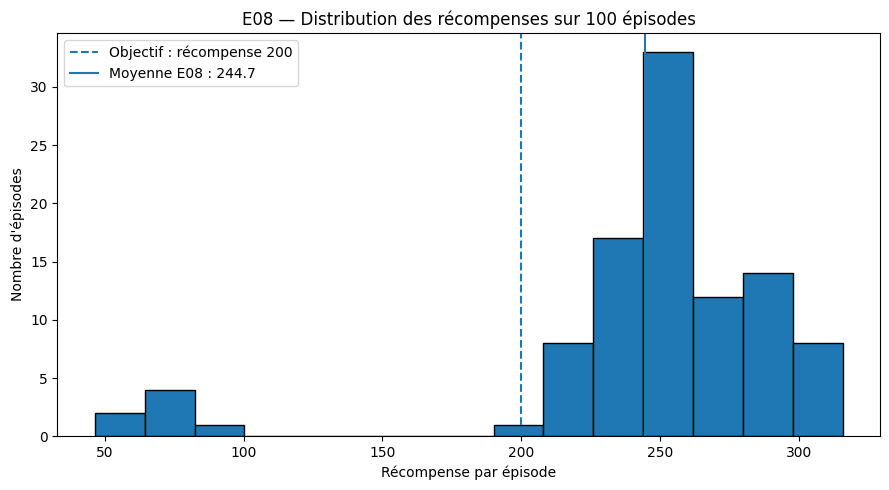

Histogramme enregistré dans : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/figures/lunarlander_E08_generalization_histogram.png


In [3]:
# Contrôle présence surapprentissage 

# ============================================================
# Analyse complémentaire de la généralisation — E07 vs E08
# Exploite les CSV existants, sans réentraînement
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(
    "/mnt/projects/vk_oc_projet11_reinforcement_learning"
)
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"

E08_FILE = METRICS_DIR / "dqn_lunarlander_E08_eval_100.csv"
COMPARISON_FILE = METRICS_DIR / "dqn_lunarlander_E07_E08_fresh_100.csv"

# --- Vérification des fichiers ---
for file in [E08_FILE, COMPARISON_FILE]:
    if not file.exists():
        raise FileNotFoundError(
            f"Fichier introuvable : {file}\n"
            "Vérifie le nom et l'emplacement du CSV."
        )

e08_df = pd.read_csv(E08_FILE)
comparison_df = pd.read_csv(COMPARISON_FILE)

print("Colonnes du CSV E08 :", e08_df.columns.tolist())
print("Colonnes du CSV comparatif :", comparison_df.columns.tolist())


# --- Identification automatique des colonnes de récompense ---
def find_reward_column(df):
    """Repère une colonne contenant les récompenses par épisode."""
    candidates = [
        c for c in df.columns
        if any(word in c.lower() for word in
               ["reward", "return", "episode_rew"])
    ]
    if len(candidates) == 1:
        return candidates[0]
    if "reward" in df.columns:
        return "reward"
    return None


def summarize_rewards(rewards, name):
    """Calcule les indicateurs utiles pour évaluer la robustesse."""
    rewards = pd.to_numeric(
        pd.Series(rewards), errors="coerce"
    ).dropna()

    if rewards.empty:
        print(f"\n{name} : aucune récompense exploitable.")
        return None

    result = {
        "Modèle / série": name,
        "Nombre d'épisodes": len(rewards),
        "Moyenne": rewards.mean(),
        "Médiane": rewards.median(),
        "Écart-type": rewards.std(ddof=1),
        "Minimum": rewards.min(),
        "Q1": rewards.quantile(0.25),
        "Q3": rewards.quantile(0.75),
        "Maximum": rewards.max(),
        "Épisodes >= 200 (%)": 100 * (rewards >= 200).mean(),
    }
    return result


# --- Analyse de la première évaluation E08 ---
e08_reward_col = find_reward_column(e08_df)

if e08_reward_col is None:
    raise ValueError(
        "Impossible d'identifier la colonne de récompense dans le "
        f"CSV E08. Colonnes disponibles : {e08_df.columns.tolist()}"
    )

e08_rewards = pd.to_numeric(
    e08_df[e08_reward_col], errors="coerce"
).dropna()

summaries = [
    summarize_rewards(e08_rewards, "E08 — évaluation initiale")
]


# --- Analyse de la comparaison sur de nouvelles graines ---
# Le fichier peut être au format large (une colonne par modèle)
# ou au format long (une colonne modèle et une colonne récompense).
comp = comparison_df.copy()
comp_reward_col = find_reward_column(comp)

model_col = next(
    (
        c for c in comp.columns
        if any(word in c.lower() for word in ["model", "agent"])
    ),
    None
)

if comp_reward_col is not None and model_col is not None:
    # Format long : une ligne par épisode et par modèle
    for model_name in ["E07", "E08"]:
        mask = comp[model_col].astype(str).str.contains(
            model_name, case=False, regex=False
        )
        if mask.any():
            summaries.append(
                summarize_rewards(
                    comp.loc[mask, comp_reward_col],
                    f"{model_name} — nouvelles graines"
                )
            )
else:
    # Format large : colonnes de récompenses séparées pour E07 et E08
    for model_name in ["E07", "E08"]:
        candidates = [
            c for c in comp.columns
            if model_name.lower() in c.lower()
            and any(word in c.lower() for word in
                    ["reward", "return", "rew"])
        ]
        if len(candidates) == 1:
            summaries.append(
                summarize_rewards(
                    comp[candidates[0]],
                    f"{model_name} — nouvelles graines"
                )
            )

# --- Tableau récapitulatif ---
summary_df = pd.DataFrame(
    [item for item in summaries if item is not None]
)

display(summary_df.round(2))

# Sauvegarde du bilan statistique
summary_path = METRICS_DIR / "lunarlander_generalization_analysis.csv"
summary_df.to_csv(summary_path, index=False)
print(f"\nBilan enregistré dans : {summary_path}")


# --- Visualisation des récompenses E08 ---
plt.figure(figsize=(9, 5))
plt.hist(e08_rewards, bins=15, edgecolor="black")
plt.axvline(
    200, linestyle="--",
    label="Objectif : récompense 200"
)
plt.axvline(
    e08_rewards.mean(), linestyle="-",
    label=f"Moyenne E08 : {e08_rewards.mean():.1f}"
)
plt.xlabel("Récompense par épisode")
plt.ylabel("Nombre d'épisodes")
plt.title("E08 — Distribution des récompenses sur 100 épisodes")
plt.legend()
plt.tight_layout()

figure_path = PROJECT_DIR / "outputs" / "figures" / \
    "lunarlander_E08_generalization_histogram.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Histogramme enregistré dans : {figure_path}")


Évaluation initiale d'E08
Nombre d'épisodes : 100
Moyenne : 244.67
Épisodes avec récompense >= 200 : 93/100

Évaluation d'E08 sur de nouvelles graines
Nombre d'épisodes : 100
Moyenne : 235.35
Épisodes avec récompense >= 200 : 85/100


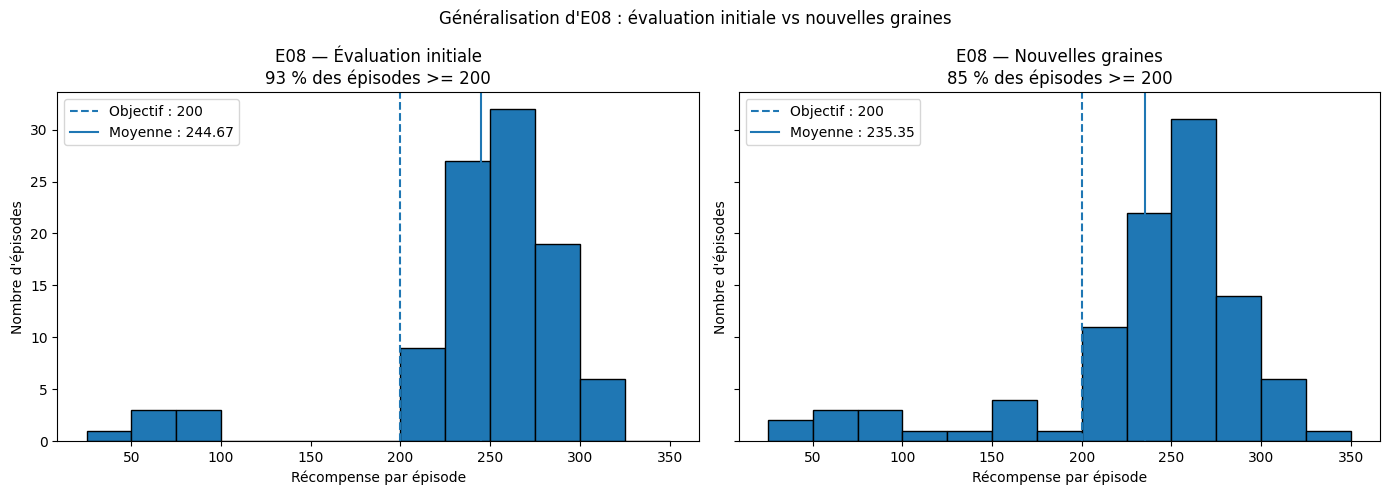


Figure enregistrée dans : /mnt/projects/vk_oc_projet11_reinforcement_learning/outputs/figures/lunarlander_E08_comparaison_generalisation.png


In [4]:

# ============================================================
# Comparaison de la généralisation d'E08
# Évaluation initiale vs nouvelles graines
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(
    "/mnt/projects/vk_oc_projet11_reinforcement_learning"
)
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Charger les résultats déjà enregistrés
initial_df = pd.read_csv(
    METRICS_DIR / "dqn_lunarlander_E08_eval_100.csv"
)
fresh_df = pd.read_csv(
    METRICS_DIR / "dqn_lunarlander_E07_E08_fresh_100.csv"
)

# Extraire les récompenses d'E08 sur les nouvelles graines
fresh_e08 = fresh_df.loc[
    fresh_df["model"].astype(str).str.upper() == "E08",
    "reward"
].dropna()

initial_e08 = initial_df["reward"].dropna()

if len(initial_e08) == 0 or len(fresh_e08) == 0:
    raise ValueError(
        "Aucune récompense trouvée pour l'une des deux évaluations. "
        "Vérifie le contenu des CSV."
    )

# Afficher les statistiques pour vérification
print("Évaluation initiale d'E08")
print(f"Nombre d'épisodes : {len(initial_e08)}")
print(f"Moyenne : {initial_e08.mean():.2f}")
print(f"Épisodes avec récompense >= 200 : "
      f"{(initial_e08 >= 200).sum()}/{len(initial_e08)}")

print("\nÉvaluation d'E08 sur de nouvelles graines")
print(f"Nombre d'épisodes : {len(fresh_e08)}")
print(f"Moyenne : {fresh_e08.mean():.2f}")
print(f"Épisodes avec récompense >= 200 : "
      f"{(fresh_e08 >= 200).sum()}/{len(fresh_e08)}")

# Utiliser les mêmes intervalles pour comparer les distributions
all_rewards = pd.concat([initial_e08, fresh_e08])
bins = range(
    int(all_rewards.min() // 25 * 25),
    int(all_rewards.max() // 25 * 25 + 50),
    25
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

evaluations = [
    (
        axes[0],
        initial_e08,
        "Évaluation initiale",
        "244,67"
    ),
    (
        axes[1],
        fresh_e08,
        "Nouvelles graines",
        "235,35"
    ),
]

for ax, rewards, label, _ in evaluations:
    ax.hist(rewards, bins=bins, edgecolor="black")
    ax.axvline(
        200,
        linestyle="--",
        label="Objectif : 200"
    )
    ax.axvline(
        rewards.mean(),
        linestyle="-",
        label=f"Moyenne : {rewards.mean():.2f}"
    )
    ax.set_title(
        f"E08 — {label}\n"
        f"{(rewards >= 200).mean() * 100:.0f} % des épisodes >= 200"
    )
    ax.set_xlabel("Récompense par épisode")
    ax.set_ylabel("Nombre d'épisodes")
    ax.legend()

fig.suptitle(
    "Généralisation d'E08 : évaluation initiale vs nouvelles graines"
)
fig.tight_layout()

figure_path = (
    FIGURES_DIR / "lunarlander_E08_comparaison_generalisation.png"
)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"\nFigure enregistrée dans : {figure_path}")


#### Analyse des résultats : E08 — test sur 100 nouvelles graines

# 235,35

récompense moyenne

#### Épisodes avec récompense ≥ 200

### 85 %

85 épisodes sur 100

#### Écart-type

### 61,85

Variabilité des résultats

Sur l’évaluation initiale de 100 épisodes, E08 avait une moyenne de 244,67, avec 93 % des épisodes à 200 ou plus.

Trois conclusions ressortent :

- **Le critère de performance est respecté :** la récompense moyenne d’E08 dépasse 200 sur les deux séries de 100 épisodes.
- **La généralisation semble bonne :** sur de nouvelles graines, la moyenne reste élevée et diminue modérément, de 244,67 à 235,35.
- **Les performances ne sont pas uniformes :** 15 épisodes sur les 100 nouvelles graines restent sous 200. L’écart-type de 61,85 montre qu’il existe encore une dispersion notable.

La comparaison avec E07 est également favorable : sur les mêmes nouvelles graines, E08 obtient 235,35 de moyenne contre 214,36 pour E07, avec un écart-type inférieur (61,85 contre 78,54).

**Cela constitue un indice solide de bonne généralisation sur les graines testées, sans toutefois prouver l’absence totale de surapprentissage.**

#### Analyse de la généralisation et du risque de surapprentissage avec E08

Le modèle E08 a été évalué sur deux séries distinctes de 100 épisodes. Lors de l’évaluation initiale, il obtient une récompense moyenne de 244,67, avec un écart-type de 54,39. Sur une nouvelle série de 100 graines, non utilisée pour cette première évaluation, la récompense moyenne atteint 235,35, avec un écart-type de 61,85. Dans cette seconde série, 85 % des épisodes obtiennent une récompense supérieure ou égale à 200.

La diminution modérée de la récompense moyenne entre les deux évaluations, associée au maintien d’un niveau de performance supérieur à l’objectif de 200, indique que les performances du modèle se maintiennent sur de nouvelles graines. La comparaison avec E07 sur ces mêmes graines montre également une amélioration de la moyenne et une réduction de la dispersion des récompenses avec E08.

**L’histogramme met néanmoins en évidence une variabilité entre les épisodes : certains atterrissages restent moins performants. Ces résultats apportent donc des éléments favorables à la capacité de généralisation de l’agent, mais ne permettent pas d’affirmer qu’il n’existe aucun surapprentissage. Cette conclusion est limitée aux conditions et aux graines évaluées.**

## Conclusion
### E08 — modèle retenu

**Fichier du modèle**

`models/dqn_lunarlander_E08_learning_rate_0001.zip`

| Indicateur | Résultat | Nombre d’épisodes |
|---|---:|---:|
| Moyenne — 1re série | 244,67 | 100 |
| Moyenne — nouvelles graines | 235,35 | 100 |
| Épisodes avec une récompense ≥ 200 — 1re série | 93 % | 100 |
| Épisodes avec une récompense ≥ 200 — nouvelles graines | 85 % | 100 |
| Écart-type — nouvelles graines | 61,85 | 100 |

E08 est donc notre meilleur candidat en termes de performances mesurées et de généralisation testée. Cela ne signifie pas qu’il est nécessairement le meilleur modèle possible.

Pour l’étape 3 : le fichier .zip sera chargé directement avec Stable-Baselines3, sans relancer l’entraînement. Le modèle sauvegardé contient les paramètres appris par l’agent qui nous servira à prendre les décisions dans l’API et dans la démonstration.